# Baseline Ensemble Performance on Imbalanced Datasets (expanded)

This notebook analyses the performance of six tree ensemble classifiers on 37 imbalanced
binary classification datasets, with no resampling or cost-sensitive adjustments applied.
It serves as the **baseline** against which all subsequent experiments (random
undersampling, IHT, cost-sensitive learning, oversampling) are compared.

It expands `01-analysis-of-ensembles.ipynb` with the results of the hyperparameter search
and a comparison with the models trained before CatBoost, LightGBM and XGBoost were tuned
with early stopping.

## Models and hyperparameter tuning

All models are tuned to maximise ROC-AUC with 3-fold stratified cross-validation on the
training set, and then refit on the full training set
(`scripts/training_scripts/train-ensembles.py`).

| Key | Algorithm | Tuning |
|-----|-----------|--------|
| `rf` | Random Forest (`RandomForestClassifier`) | Successive halving (`HalvingRandomSearchCV`) with the number of trees as the resource (10 to 1000). |
| `ada` | AdaBoost (`AdaBoostClassifier`) | Successive halving as for `rf`, over the learning rate. |
| `gbm` | Gradient Boosting (`GradientBoostingClassifier`) | Successive halving as for `rf`. In addition, each model stops adding trees when the loss on an internal validation split (10% of the training data) has not improved for 20 rounds (`n_iter_no_change=20`). |
| `cat` | CatBoost (native API) | 100 Optuna trials (random sampler, successive-halving pruner starting at 50 rounds). On each fold, boosting stops when the validation ROC-AUC has not improved for 50 rounds (max 2000). The best candidate is refit with the mean number of rounds at which it stopped. |
| `lgbm` | LightGBM (native API) | As `cat`. |
| `xgb` | XGBoost (native API) | As `cat`. |

`cat`, `lgbm` and `xgb` are saved as `TunedBooster` objects (`functions/cv_boosting.py`),
and `rf`, `ada` and `gbm` as the fitted `HalvingRandomSearchCV`. All of them expose
`predict_proba`.

Before this procedure, all six models were tuned with successive halving over the number
of trees (SH), as `rf` and `ada` still are, and `gbm` had no early stopping. The section
at the end of the notebook compares the two.


In [1]:
import sys
sys.path.insert(1, '../')

In [2]:
import joblib
import pickle

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import precision_recall_curve, roc_curve

from functions.data import load_dataset
from functions.data import DATASETS_LS as datasets
from functions.analysis import create_df, create_fold_df
from functions.statistical_tests import apply_friedman_test, apply_nemenyi_test
from functions.plotting import compute_ylim, add_significance_bars

In [3]:
import warnings
warnings.filterwarnings("ignore", message="X does not have valid feature names")
warnings.filterwarnings("ignore", message="The total space of parameters")
warnings.simplefilter(action='ignore', category=FutureWarning)
warnings.simplefilter(action='ignore', category=UserWarning)

## Load results

In [4]:
# file contains the metric values per bootrstrap sample
filename = '../models/ensembles/results_folds'
with open(filename, 'rb') as f:
    folds_dict = pickle.load(f)

In [5]:
df = create_fold_df(folds_dict, "oil", "roc")
df

,rf,ada,gbm,cat,lgbm,xgb
0,0.918259,0.964968,0.829087,0.957006,0.939490,0.943206
1,0.976708,0.974379,0.783385,0.984472,0.937888,0.970497
2,0.977273,0.980303,0.889394,0.975758,0.943939,0.946970
3,0.958573,0.984465,0.896433,0.969505,0.958573,0.964902
4,0.943750,0.972222,0.909722,0.968056,0.948611,0.959028


In [6]:
# file contains mean metric value plus std
filename = '../models/ensembles/results'
with open(filename, 'rb') as f:
    scores_dict = pickle.load(f)

In [7]:
models = [
  "rf", "ada", "gbm", "cat", "lgbm", "xgb",
  ]

In [8]:
df = create_df(scores_dict, "oil", models)
df.shape

(6, 20)

In [9]:
# test function
df = create_df(scores_dict, "scene", models)
df

,roc,roc_std,ap,ap_std,precision,precision_std,recall,recall_std,f1_score,f1_std,mcc,mcc_std,ba,ba_std,brier,brier_std,gmean,gmean_std,thresh,tresh_std
rf,0.766026,0.030985,0.319567,0.057933,0.410665,0.118809,0.352857,0.104552,0.359683,0.063317,0.327593,0.058952,0.722860,0.013790,0.078553,0.003442,0.709681,0.023233,0.164677,0.032434
ada,0.726692,0.048490,0.300648,0.080888,0.423283,0.185572,0.357619,0.067114,0.360078,0.063639,0.318114,0.080905,0.686448,0.038432,0.197336,0.001778,0.680660,0.042073,0.477656,0.007483
gbm,0.774170,0.022713,0.300043,0.034317,0.393667,0.085248,0.400952,0.045534,0.387315,0.030558,0.338763,0.034775,0.726304,0.027484,0.080054,0.003542,0.721132,0.031796,0.122222,0.028380
cat,0.801991,0.033656,0.360416,0.050323,0.425948,0.117683,0.451429,0.109817,0.420918,0.056360,0.385031,0.057144,0.751809,0.029482,0.077874,0.003729,0.746490,0.031547,0.120651,0.039609
lgbm,0.801514,0.015833,0.339031,0.041596,0.460359,0.132710,0.414762,0.166601,0.389836,0.029786,0.366208,0.027022,0.773168,0.028484,0.091332,0.003711,0.759021,0.030079,0.002634,0.001547
xgb,0.803778,0.032582,0.391354,0.047367,0.427473,0.173076,0.458095,0.113455,0.402777,0.043528,0.392072,0.052132,0.754632,0.027078,0.077463,0.003778,0.749360,0.027587,0.102762,0.038807


## Datasets

In [10]:
datasets

['abalone_19',
 'car_eval_4',
 'coil_2000',
 'ecoli',
 'isolet',
 'letter_img',
 'libras_move',
 'mammography',
 'oil',
 'optical_digits',
 'ozone_level',
 'pen_digits',
 'protein_homo',
 'satimage',
 'scene',
 'sick_euthyroid',
 'solar_flare_m0',
 'spectrometer',
 'thyroid_sick',
 'us_crime',
 'webpage',
 'wine_quality',
 'yeast_me2',
 'cleveland-0_vs_4',
 'glass-0-1-4-6_vs_2',
 'led7digit-0-2-4-5-6-7-8-9_vs_1',
 'page-blocks-1-3_vs_4',
 'pima',
 'poker-8-9_vs_5',
 'diabetes130',
 'default_credit',
 'htru2',
 'credit_fraud',
 'secom',
 'bank-marketing',
 'telco',
 'adult']

In [11]:
# the number of datasets to analyse
len(datasets)

37




In [12]:
n_datasets = len(datasets)
n_estimators = len(["rf", "ada", "gbm", "cat", "lgbm", "xgb"])

fig, axes = plt.subplots(n_datasets, n_estimators,
                         figsize=(4 * n_estimators, 3 * n_datasets))

MODELS_DIR = "../models/ensembles"

for i, dataset in enumerate(datasets):
    _, X_test, _, y_test = load_dataset(dataset)

    for j, estimator in enumerate(["rf", "ada", "gbm", "cat", "lgbm", "xgb"]):
        search = joblib.load(f"{MODELS_DIR}/{dataset}_{estimator}.pkl")
        probs = search.predict_proba(X_test)[:, 1]

        ax = axes[i, j]
        ax.hist(probs, bins=30, density=True, color="steelblue")
        ax.set_xlim(0, 1)
        stats_text = (
            f"min={probs.min():.2f}\n"
            f"max={probs.max():.2f}\n"
            f"mean={probs.mean():.2f}\n"
            f"p75={np.percentile(probs, 75):.2f}\n"
            f"p25={np.percentile(probs, 25):.2f}"
        )
        ax.text(0.97, 0.97, stats_text,
                transform=ax.transAxes,
                fontsize=7,
                verticalalignment="top",
                horizontalalignment="right",
                bbox=dict(boxstyle="round,pad=0.3", facecolor="white", edgecolor="gray", alpha=0.8))
        ax.set_title(f"{dataset}\n{estimator}", fontsize=9)

        if j == 0:
            ax.set_ylabel("Density", fontsize=9)
        if i == n_datasets - 1:
            ax.set_xlabel("P(class = 1)", fontsize=9)

plt.suptitle("Predicted Probability of Class 1", fontsize=14, y=1.01)
plt.tight_layout()
plt.savefig('../figures/ensembles_expanded_prob_dist.png', dpi=900, bbox_inches='tight')
plt.show()

AdaBoost squeezes the probabilities towards the centre: on most datasets they fall roughly between 0.25 and 0.7, even when the minority class makes up only 1–5% of the data (e.g. `oil`, `abalone_19`). The other models return low and high probabilities, as expected for fairly well calibrated models. On some small datasets, `gbm` and `lgbm` return only a few dozen distinct probabilities (e.g. `oil`), which show as tall spikes in the histograms.

## Training speed

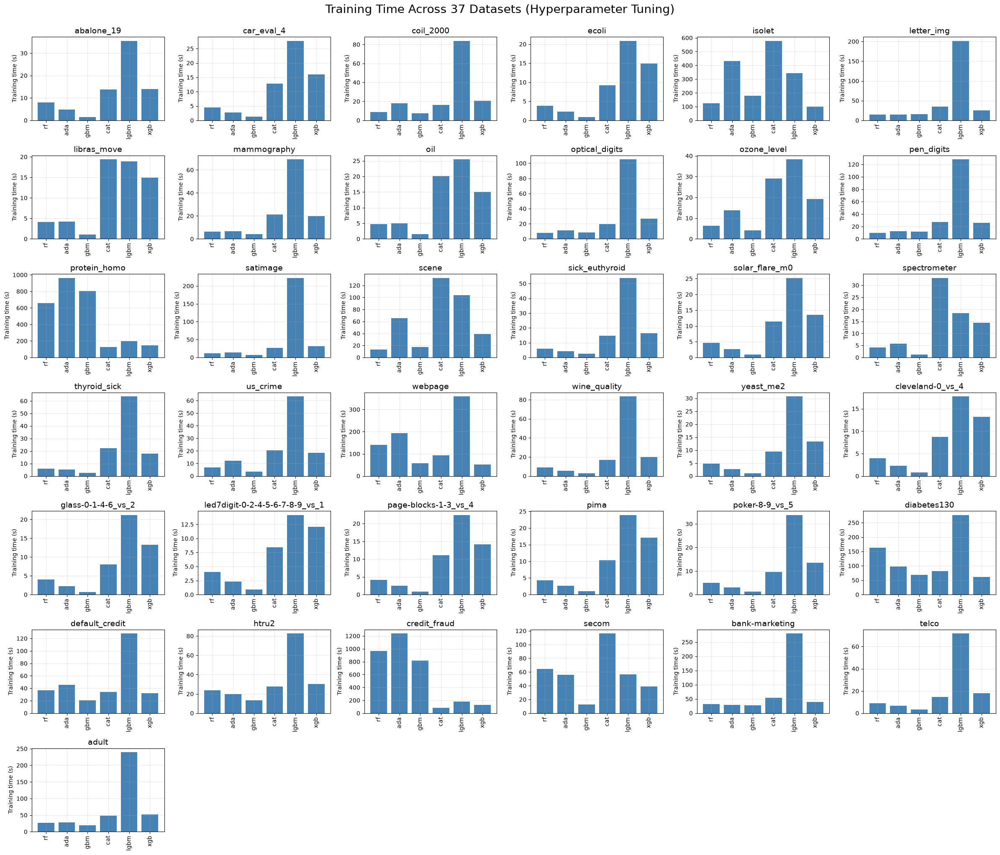

In [13]:
# Create figure with 37 subplots
fig, axes = plt.subplots(nrows=7, ncols=6, figsize=(24, 20))  # 7x6 grid for 37 plots (with 5 empty)
axes = axes.ravel()  # Flatten for easy iteration

# Loop through each dataset
for i, data in enumerate(datasets):
    ax = axes[i]

    # collect training time (with hyperparameter tuning) per model
    fit_times = []
    for estimator in models:
        search = joblib.load(f"../models/ensembles/{data}_{estimator}.pkl")
        fit_times.append(search.fit_time)

    ax.bar(models, fit_times, color="steelblue")

    # Customize subplot
    ax.set_title(data, fontsize=14)
    ax.set_ylabel("Training time (s)", fontsize=10)
    ax.tick_params(axis='x', rotation=90, labelsize=10)
    ax.grid(True, alpha=0.3)

# Hide unused subplots
for j in range(i+1, len(axes)):
    axes[j].axis('off')

plt.tight_layout()
plt.suptitle(f'Training Time Across {len(datasets)} Datasets (Hyperparameter Tuning)', fontsize=20, y=1.02)
plt.savefig('../figures/ensembles_expanded_training_time.png', dpi=300, bbox_inches='tight')
plt.show()

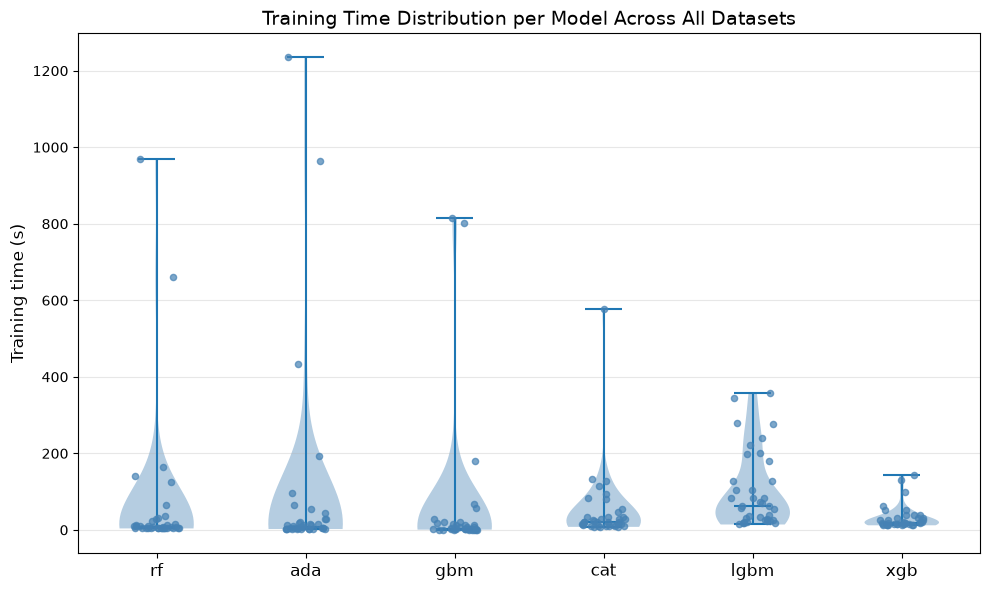

Median training time (s) per model:
model
rf       7.8
ada      6.8
gbm      3.5
cat     20.5
lgbm    63.5
xgb     19.1


In [14]:
# Collect training times: one value per (model, dataset) combination
fit_time_rows = []
for data in datasets:
    for estimator in models:
        search = joblib.load(f"../models/ensembles/{data}_{estimator}.pkl")
        fit_time_rows.append({"model": estimator, "fit_time": search.fit_time})

fit_time_df = pd.DataFrame(fit_time_rows)

fig, ax = plt.subplots(figsize=(10, 6))

# Violin
parts = ax.violinplot(
    [fit_time_df.loc[fit_time_df["model"] == m, "fit_time"].values for m in models],
    positions=range(len(models)),
    showmedians=True,
    showextrema=True,
)
for pc in parts["bodies"]:
    pc.set_facecolor("steelblue")
    pc.set_alpha(0.4)

# Jittered scatter on top
rng = np.random.default_rng(0)
for k, m in enumerate(models):
    times = fit_time_df.loc[fit_time_df["model"] == m, "fit_time"].values
    jitter = rng.uniform(-0.15, 0.15, size=len(times))
    ax.scatter(k + jitter, times, s=20, color="steelblue", alpha=0.7, zorder=3)

ax.set_xticks(range(len(models)))
ax.set_xticklabels(models, fontsize=12)
ax.set_ylabel("Training time (s)", fontsize=12)
ax.set_title("Training Time Distribution per Model Across All Datasets", fontsize=14)
ax.grid(True, alpha=0.3, axis="y")

plt.tight_layout()
plt.savefig('../figures/ensembles_expanded_training_time_summary.png', dpi=300, bbox_inches='tight')
plt.show()

# Print median training times for reference
print("Median training time (s) per model:")
print(fit_time_df.groupby("model")["fit_time"].median().reindex(models).round(1).to_string())

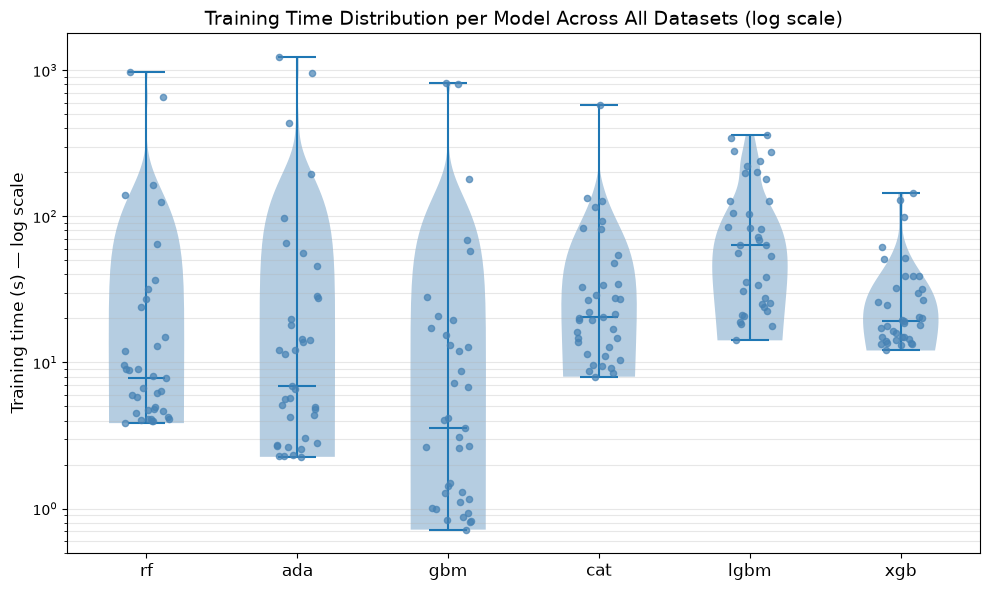

In [15]:
# Same plot on a log y-axis — compresses the extreme outliers so the
# median differences between models become visible
fig, ax = plt.subplots(figsize=(10, 6))

parts = ax.violinplot(
    [fit_time_df.loc[fit_time_df["model"] == m, "fit_time"].values for m in models],
    positions=range(len(models)),
    showmedians=True,
    showextrema=True,
)
for pc in parts["bodies"]:
    pc.set_facecolor("steelblue")
    pc.set_alpha(0.4)

rng2 = np.random.default_rng(0)
for k, m in enumerate(models):
    times = fit_time_df.loc[fit_time_df["model"] == m, "fit_time"].values
    jitter = rng2.uniform(-0.15, 0.15, size=len(times))
    ax.scatter(k + jitter, times, s=20, color="steelblue", alpha=0.7, zorder=3)

ax.set_yscale("log")
ax.set_xticks(range(len(models)))
ax.set_xticklabels(models, fontsize=12)
ax.set_ylabel("Training time (s) — log scale", fontsize=12)
ax.set_title("Training Time Distribution per Model Across All Datasets (log scale)", fontsize=14)
ax.grid(True, alpha=0.3, axis="y", which="both")

plt.tight_layout()
plt.savefig('../figures/ensembles_expanded_training_time_summary_log.png', dpi=300, bbox_inches='tight')
plt.show()

Training times include the hyperparameter search. Median training time per model:

- **`gbm` is the fastest** — median ≈ 3.5 s.
- `ada` (7 s) and `rf` (8 s) follow.
- `xgb` (19 s) and `cat` (21 s) are slower.
- **`lgbm` is the slowest** — median ≈ 64 s.

`rf` and `ada` are tuned exactly as in the SH run, yet their median times dropped from 14 s and 23 s (as reported in `01-analysis-of-ensembles.ipynb`) to 8 s and 7 s. Differences in time between the two runs are therefore partly due to machine load. Even so, early stopping makes `gbm` much cheaper to tune (SH median 20 s), while `lgbm` (SH 28 s) and `xgb` (SH 3 s) became slower: with a patience of 50 rounds, each of the 100 Optuna trials trains for at least 50 extra rounds on every fold.

## Hyperparameter search results

Number of trees (boosting rounds), learning rate and cross-validated ROC-AUC of the
selected model. For `gbm`, the number of trees is the one reached after early stopping
(`n_estimators_`).

In [16]:
def tuning_summary(model, estimator):
    """Return number of trees, learning rate and CV ROC-AUC of the selected model."""
    if estimator in ("cat", "lgbm", "xgb"):
        return model.best_num_rounds_, model.best_params_["learning_rate"], model.best_score_
    best = model.best_estimator_
    if estimator == "gbm":
        return best.n_estimators_, best.learning_rate, model.best_score_
    if estimator == "ada":
        return best.n_estimators, best.learning_rate, model.best_score_
    return best.n_estimators, np.nan, model.best_score_


tuning_rows = []
for data in datasets:
    for estimator in models:
        model = joblib.load(f"../models/ensembles/{data}_{estimator}.pkl")
        n_trees, lr, cv_roc = tuning_summary(model, estimator)
        tuning_rows.append({
            "dataset": data, "model": estimator, "n_trees": n_trees,
            "learning_rate": lr, "cv_roc": cv_roc,
            "test_roc": scores_dict[data][estimator][0],
        })

tuning_df = pd.DataFrame(tuning_rows)
tuning_df.pivot(index="dataset", columns="model", values="n_trees")[models]

model,rf,ada,gbm,cat,lgbm,xgb
dataset,,,,,,
abalone_19,810,810,50,75,52,29
adult,810,810,146,296,116,826
bank-marketing,810,810,207,271,232,449
car_eval_4,810,810,138,81,17,62
cleveland-0_vs_4,810,810,81,12,6,18
coil_2000,810,810,119,63,95,63
credit_fraud,810,810,125,75,169,149
default_credit,810,810,117,64,68,224
diabetes130,810,810,132,279,165,135


In [17]:
tuning_df.groupby("model")[["n_trees", "learning_rate"]].describe().loc[models].round(3).T

model                   rf      ada      gbm      cat     lgbm      xgb
n_trees       count   37.0   37.000   37.000   37.000   37.000   37.000
              mean   810.0  810.000  110.162  134.514   92.541  141.703
              std      0.0    0.000   79.036  116.453   84.913  183.792
              min    810.0  810.000   21.000    4.000    6.000    9.000
              25%    810.0  810.000   41.000   41.000   28.000   36.000
              50%    810.0  810.000   85.000   94.000   68.000   62.000
              75%    810.0  810.000  157.000  234.000  127.000  137.000
              max    810.0  810.000  303.000  476.000  378.000  826.000
learning_rate count    0.0   37.000   37.000   37.000   37.000   37.000
              mean     NaN    0.686    0.227    0.170    0.172    0.101
              std      NaN    0.245    0.270    0.159    0.222    0.102
              min      NaN    0.004    0.017    0.010    0.010    0.022
              25%      NaN    0.520    0.031    0.062    0.030    0.039
              50%      NaN    0.722    0.107    0.112    0.101    0.048
              75%      NaN    0.918    0.409    0.190    0.174    0.131
              max      NaN    0.988    0.962    0.717    0.945    0.391

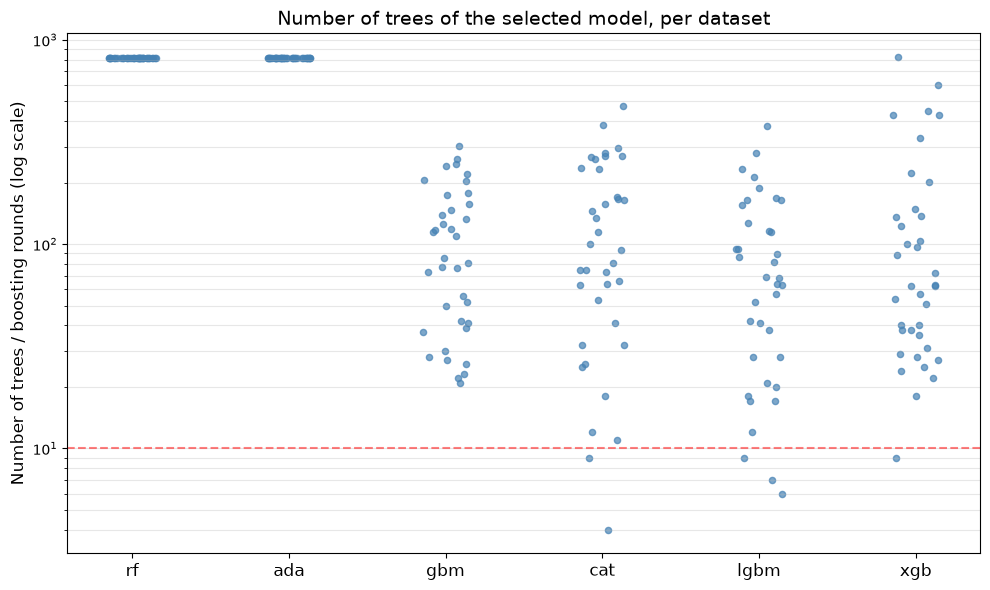

Datasets where the selected model has fewer than 10 trees:
model
rf      0
ada     0
gbm     0
cat     2
lgbm    3
xgb     1


In [18]:
fig, ax = plt.subplots(figsize=(10, 6))

rng = np.random.default_rng(0)
for k, m in enumerate(models):
    n_trees = tuning_df.loc[tuning_df["model"] == m, "n_trees"].values
    jitter = rng.uniform(-0.15, 0.15, size=len(n_trees))
    ax.scatter(k + jitter, n_trees, s=20, color="steelblue", alpha=0.7)

ax.axhline(y=10, color="r", linestyle="--", alpha=0.5)
ax.set_yscale("log")
ax.set_xticks(range(len(models)))
ax.set_xticklabels(models, fontsize=12)
ax.set_ylabel("Number of trees / boosting rounds (log scale)", fontsize=12)
ax.set_title("Number of trees of the selected model, per dataset", fontsize=14)
ax.grid(True, alpha=0.3, axis="y", which="both")

plt.tight_layout()
plt.savefig('../figures/ensembles_expanded_n_trees.png', dpi=300, bbox_inches='tight')
plt.show()

print("Datasets where the selected model has fewer than 10 trees:")
print((tuning_df["n_trees"] < 10).groupby(tuning_df["model"]).sum().reindex(models).to_string())

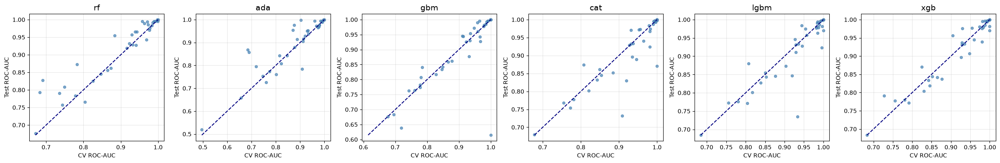

,count,mean,std,min,25%,50%,75%,max
model,,,,,,,,
rf,37.0,0.017,0.036,-0.038,-0.001,0.004,0.026,0.137
ada,37.0,0.018,0.054,-0.124,-0.002,0.004,0.024,0.184
gbm,37.0,-0.010,0.068,-0.385,-0.007,0.000,0.006,0.055
cat,37.0,-0.014,0.043,-0.177,-0.018,-0.002,0.002,0.067
lgbm,37.0,-0.011,0.041,-0.199,-0.018,-0.003,0.003,0.072
xgb,37.0,-0.001,0.025,-0.041,-0.019,-0.000,0.006,0.064


In [19]:
# Cross-validated ROC-AUC (training set) vs ROC-AUC on the test set
cv_models = models

fig, axes = plt.subplots(1, len(cv_models), figsize=(4 * len(cv_models), 4))

for ax, m in zip(axes, cv_models):
    df = tuning_df[tuning_df["model"] == m]
    ax.scatter(df["cv_roc"], df["test_roc"], s=20, color="steelblue", alpha=0.7)
    lims = [min(df["cv_roc"].min(), df["test_roc"].min()), 1]
    ax.plot(lims, lims, color="navy", linestyle="--")
    ax.set_title(m, fontsize=14)
    ax.set_xlabel("CV ROC-AUC")
    ax.set_ylabel("Test ROC-AUC")
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('../figures/ensembles_expanded_cv_vs_test_roc.png', dpi=300, bbox_inches='tight')
plt.show()

(tuning_df["test_roc"] - tuning_df["cv_roc"]).groupby(tuning_df["model"]).describe().reindex(cv_models).round(3)

### Hyperparameter search conclusion

With a patience of 50 rounds, the boosting models keep a reasonable number of rounds. The median is 62 for `xgb`, 68 for `lgbm`, 85 for `gbm` and 94 for `cat`, with up to 476 (`cat`) and 826 (`xgb`) rounds on the larger datasets. Fewer than 10 rounds are kept on only 1–3 datasets per model, compared with 9–20 datasets when the patience was 3. `rf` and `ada` always keep 810 trees, the largest number of trees reached by successive halving.

The median learning rates of the boosting models are around 0.1 (0.05 for `xgb`). AdaBoost selects high learning rates (median 0.72).

For all models, the cross-validated ROC-AUC is a fair estimate of the test ROC-AUC (median difference ≈ 0). For `gbm`, `cat` and `lgbm`, the test ROC-AUC falls well below the CV estimate on a few small datasets (down to -0.39 for `gbm`). `xgb` is the most stable (minimum -0.04).

## ROC-AUC Friedman test

In [20]:
friedman_rows = []
nemenyi_dict = {}

for data in datasets:
    df = create_fold_df(folds_dict, data, "roc")
    statistic, pvalue = apply_friedman_test(df)
    friedman_rows.append({"dataset": data, "statistic": statistic, "pvalue": pvalue})

    # follow up with Nemenyi post-hoc test only when Friedman is significant
    if pvalue < 0.05:
        nemenyi_dict[data] = apply_nemenyi_test(df)

friedman_df = pd.DataFrame(friedman_rows).set_index("dataset")
friedman_df

,statistic,pvalue
dataset,,
abalone_19,13.114286,0.022331
car_eval_4,15.590278,0.008117
coil_2000,14.714286,0.011656
ecoli,8.558282,0.128034
isolet,21.228571,0.000733
letter_img,23.352601,0.000289
libras_move,6.496063,0.260895
mammography,14.600000,0.012215
oil,20.200000,0.001146


In [21]:
nemenyi_dict["coil_2000"]

,rf,ada,gbm,cat,lgbm,xgb
rf,1.000000,0.984591,0.995925,0.845079,0.238812,0.168134
ada,0.984591,1.000000,0.845079,0.427525,0.046736,0.028372
gbm,0.995925,0.845079,1.000000,0.984591,0.538193,0.427525
cat,0.845079,0.427525,0.984591,1.000000,0.913410,0.845079
lgbm,0.238812,0.046736,0.538193,0.913410,1.000000,0.999981
xgb,0.168134,0.028372,0.427525,0.845079,0.999981,1.000000


## Plot ROC-AUC

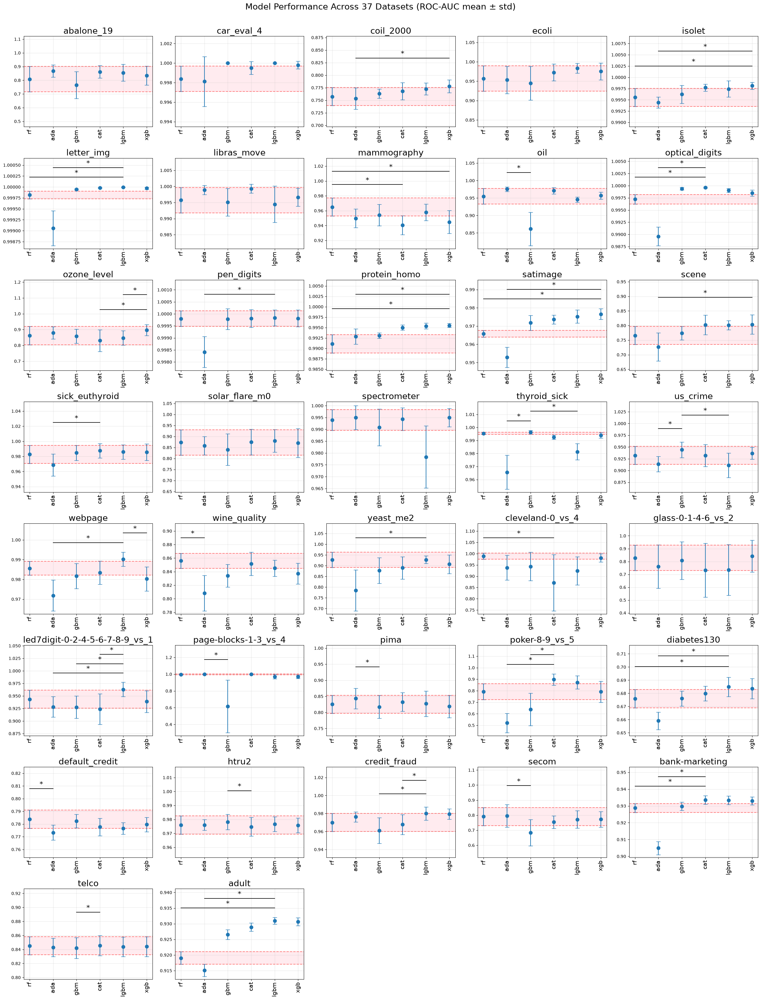

In [22]:
# Create figure with 37 subplots
fig, axes = plt.subplots(nrows=8, ncols=5, figsize=(25, 32))  # 8x5 grid for 37 plots (with 3 empty)
axes = axes.ravel()  # Flatten for easy iteration

# Loop through each DataFrame
for i, data in enumerate(datasets):
    df = create_df(scores_dict, data, models)

    ax = axes[i]

    # Extract data
    cls = df.index
    means = df.iloc[:, 0]
    stds = df.iloc[:, 1]

    upper = df.iloc[0, 0] + df.iloc[0, 1]
    lower = df.iloc[0, 0] - df.iloc[0, 1]

    # Determine significant comparisons (if any) up front, so we can
    # reserve extra headroom above the data for the significance bars
    best_model = None
    sig_models = []
    if data in nemenyi_dict:
        best_model = means.idxmax()
        posthoc = nemenyi_dict[data]
        sig_models = [
            m for m in models
            if m != best_model and posthoc.loc[best_model, m] < 0.05
        ]

    # Create errorbar plot
    ax.errorbar(x=cls, y=means, yerr=stds,
               fmt='o', capsize=5, markersize=8)

    # Customize subplot
    ax.set_title(data, fontsize=20)
    ylims = compute_ylim(means, stds, upper, lower)
    if sig_models:
        # reserve headroom above the data for the significance bars
        y0, y1 = ylims
        ylims = (y0, y1 + (y1 - y0) * 0.4)
    ax.set_ylim(ylims)
    ax.tick_params(axis='x', rotation=90, labelsize=14)
    ax.grid(True, alpha=0.3)

    # Add horizontal lines at random forest error bars
    ax.axhline(y=upper, color='r', linestyle='--', alpha=0.5)
    ax.axhline(y=lower, color='r', linestyle='--', alpha=0.5)

    # color between RF error bars
    ax.axhspan(ymin=lower, ymax=upper, facecolor='pink', alpha=0.3)

    # If the Friedman test was significant, draw Nemenyi significance bars
    # from the best performing model to each model significantly worse than it
    if sig_models:
        data_max = (means + stds).max()
        add_significance_bars(ax, models, data_max, best_model, sig_models)

# Hide unused subplotsc
for j in range(i+1, len(axes)):
    axes[j].axis('off')

plt.tight_layout()
plt.suptitle(f'Model Performance Across {len(datasets)} Datasets (ROC-AUC mean ± std)', fontsize=20, y=1.02)
plt.savefig('../figures/ensembles_expanded_rocauc.png', dpi=300, bbox_inches='tight')
plt.show()

### ROC-AUC conclusion

The Friedman test is significant for 33 out of 37 datasets (not for `ecoli`, `libras_move`, `solar_flare_m0` and `glass-0-1-4-6_vs_2`). The Nemenyi post-hoc comparisons do not reveal a single dominant algorithm. Ranked by mean rank across datasets, `xgb` (2.8) and `lgbm` (2.9) lead, followed by `cat` (3.2), `rf` (3.5), `gbm` (4.2) and `ada` (4.5). `lgbm` is the best model on 10 datasets and `xgb` on 8. The native gradient boosting implementations tend to sit at the top, but which of them wins varies by dataset.

## Plot ROC curves

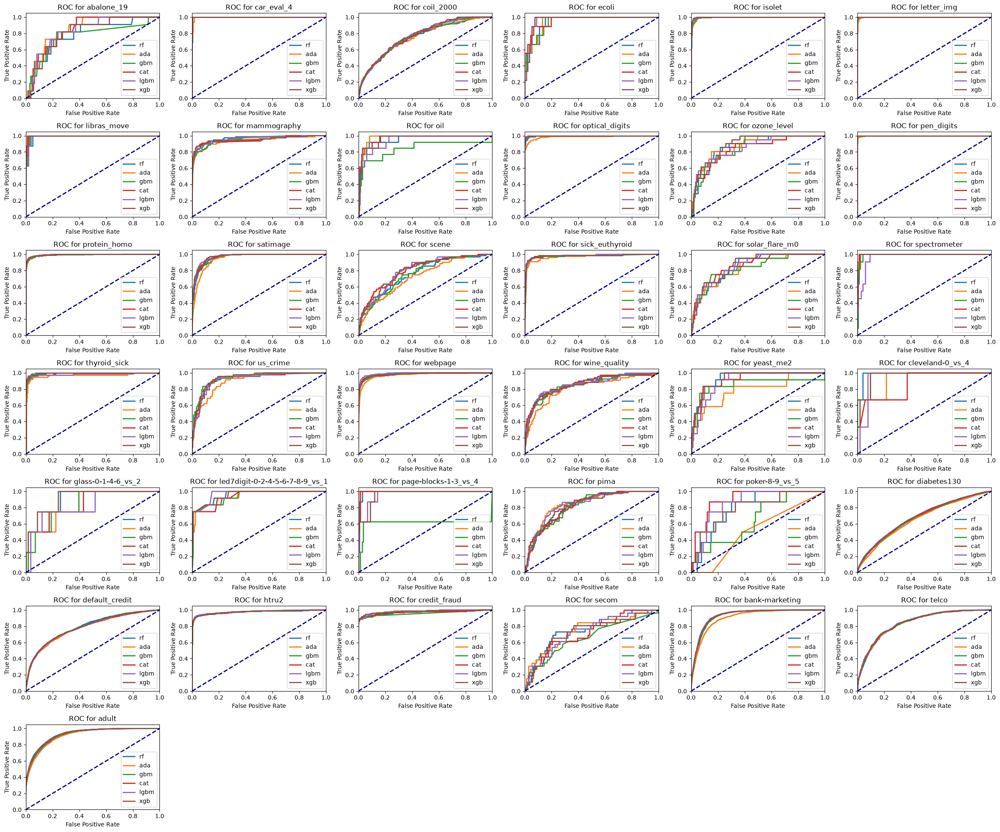

In [23]:
# Create figure with 37 subplots
fig, axes = plt.subplots(nrows=7, ncols=6, figsize=(24, 20))  # 7x6 grid for 37 plots (with 5 empty)
axes = axes.ravel()  # Flatten for easy iteration

# Loop through each DataFrame
for i, data in enumerate(datasets):
    ax = axes[i]

    # load data
    X_train, X_test, y_train, y_test = load_dataset(data)
    
    # For each model type
    for estimator in models:
        
        # load model
        search = joblib.load(f"../models/ensembles/{data}_{estimator}.pkl")

        # obtain probability
        prob = search.predict_proba(X_test)[:, 1]
        
        # Plot ROC curve
        fpr, tpr, _ =  roc_curve(y_test, prob)
        ax.plot(fpr, tpr, lw=2, label=f'{estimator}')
    
    # Format the plot
    ax.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
    ax.set_xlim([0.0, 1.0])
    ax.set_ylim([0.0, 1.05])
    ax.set_xlabel('False Positive Rate')
    ax.set_ylabel('True Positive Rate')
    ax.set_title(f'ROC for {data}')
    ax.legend(loc="lower right")

# Hide empty subplots if any
for j in range(i+1, len(axes)):
    axes[j].axis('off')

plt.tight_layout()
plt.savefig('../figures/ensembles_expanded_roc_curves.png', dpi=300, bbox_inches='tight')
plt.show()

## Average Precision Friedman test

In [24]:
friedman_rows = []
nemenyi_dict_ap = {}

for data in datasets:
    df = create_fold_df(folds_dict, data, "ap")
    statistic, pvalue = apply_friedman_test(df)
    friedman_rows.append({"dataset": data, "statistic": statistic, "pvalue": pvalue})

    # follow up with Nemenyi post-hoc test only when Friedman is significant
    if pvalue < 0.05:
        nemenyi_dict_ap[data] = apply_nemenyi_test(df)

friedman_df_ap = pd.DataFrame(friedman_rows).set_index("dataset")
friedman_df_ap

,statistic,pvalue
dataset,,
abalone_19,10.600000,0.059914
car_eval_4,17.573529,0.003531
coil_2000,1.685714,0.890695
ecoli,8.703704,0.121482
isolet,21.114286,0.000771
letter_img,21.571429,0.000631
libras_move,7.421875,0.191107
mammography,22.485714,0.000423
oil,19.057143,0.001876


## Plot average precision

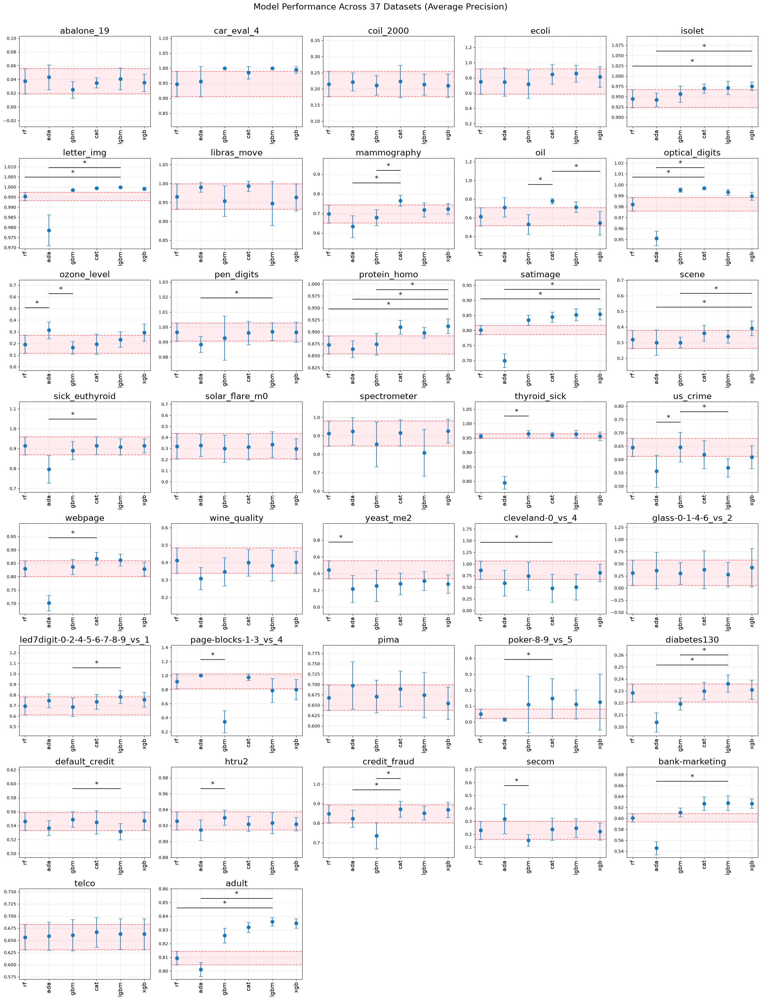

In [25]:
# Create figure with 37 subplots
fig, axes = plt.subplots(nrows=8, ncols=5, figsize=(25, 32))  # 8x5 grid for 37 plots (with 3 empty)
axes = axes.ravel()  # Flatten for easy iteration

# Loop through each DataFrame
for i, data in enumerate(datasets):
    df = create_df(scores_dict, data, models)
    
    ax = axes[i]
    
    # Extract data
    cls = df.index
    means = df.iloc[:, 2]
    stds = df.iloc[:, 3]

    upper = df.iloc[0, 2] + df.iloc[0, 3]
    lower = df.iloc[0, 2] - df.iloc[0, 3]

    # Determine significant comparisons (if any) up front, so we can
    # reserve extra headroom above the data for the significance bars
    best_model = None
    sig_models = []
    if data in nemenyi_dict_ap:
        best_model = means.idxmax()
        posthoc = nemenyi_dict_ap[data]
        sig_models = [
            m for m in models
            if m != best_model and posthoc.loc[best_model, m] < 0.05
        ]

    # Create errorbar plot
    ax.errorbar(x=cls, y=means, yerr=stds,
                fmt='o', capsize=5, markersize=8)

    # Customize subplot
    ax.set_title(data, fontsize=20)
    ylims = compute_ylim(means, stds, upper, lower)
    if sig_models:
        # reserve headroom above the data for the significance bars
        y0, y1 = ylims
        ylims = (y0, y1 + (y1 - y0) * 0.4)
    ax.set_ylim(ylims)
    ax.tick_params(axis='x', rotation=90, labelsize=14)
    ax.grid(True, alpha=0.3)

    # Add horizontal lines at RF error bars
    ax.axhline(y=upper, color='r', linestyle='--', alpha=0.5)
    ax.axhline(y=lower, color='r', linestyle='--', alpha=0.5)

    # Color area between RF error bars
    ax.axhspan(ymin=lower, ymax=upper, facecolor='pink', alpha=0.3)

    # If the Friedman test was significant, draw Nemenyi significance bars
    # from the best performing model to each model significantly worse than it
    if sig_models:
        data_max = (means + stds).max()
        add_significance_bars(ax, models, data_max, best_model, sig_models)

# Hide unused subplots
for j in range(i+1, len(axes)):
    axes[j].axis('off')

plt.tight_layout()
plt.suptitle(f'Model Performance Across {len(datasets)} Datasets (Average Precision)', fontsize=20, y=1.02)
plt.savefig('../figures/ensembles_expanded_ap.png', dpi=300, bbox_inches='tight')
plt.show()

### Average Precision conclusion

The Friedman test is significant for 28 out of 37 datasets. It is not significant for `abalone_19`, `coil_2000`, `ecoli`, `libras_move`, `solar_flare_m0`, `wine_quality`, `glass-0-1-4-6_vs_2`, `pima` and `telco`. `cat` has the best mean rank (2.6) and is the best model on 10 datasets, followed by `lgbm` (2.9), `xgb` (3.0), `rf` (3.8), `gbm` (4.3) and `ada` (4.4). No model is consistently and significantly superior to all others.

## Plot PR curves

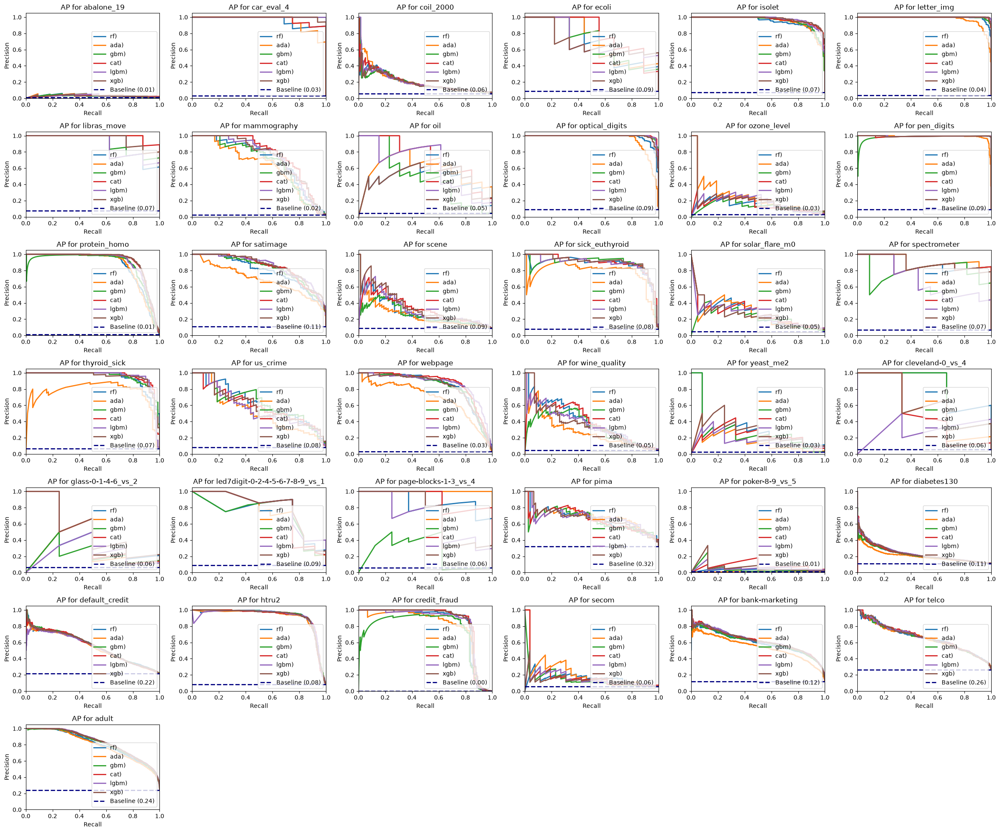

In [26]:
# Create figure with 37 subplots
fig, axes = plt.subplots(nrows=7, ncols=6, figsize=(24, 20))  # 7x6 grid for 37 plots (with 5 empty)
axes = axes.ravel()  # Flatten for easy iteration

# Loop through each DataFrame
for i, data in enumerate(datasets):
    ax = axes[i]

    # load data
    X_train, X_test, y_train, y_test = load_dataset(data)
    
    # For each model type
    for estimator in models:
        
        # load model
        search = joblib.load(f"../models/ensembles/{data}_{estimator}.pkl")

        # obtain probability
        prob = search.predict_proba(X_test)[:, 1]

        # Compute PR curve
        precision, recall, _ = precision_recall_curve(y_test, prob)

        # Plot PR curve
        ax.plot(recall, precision, lw=2, label=f'{estimator})')
    
    # Baseline
    baseline = y_test.mean()
    ax.axhline(y=baseline, color='navy', lw=2, linestyle='--', label=f'Baseline ({baseline:.2f})')

    # Format the plot
    ax.set_xlim([0.0, 1.0])
    ax.set_ylim([0.0, 1.05])
    ax.set_xlabel('Recall')
    ax.set_ylabel('Precision')
    ax.set_title(f'AP for {data}')
    ax.legend(loc="lower right")

# Hide empty subplots if any
for j in range(i+1, len(axes)):
    axes[j].axis('off')

plt.tight_layout()
plt.savefig('../figures/ensembles_expanded_pr_curves.png', dpi=300, bbox_inches='tight')
plt.show()

## AP vs ROC-AUC

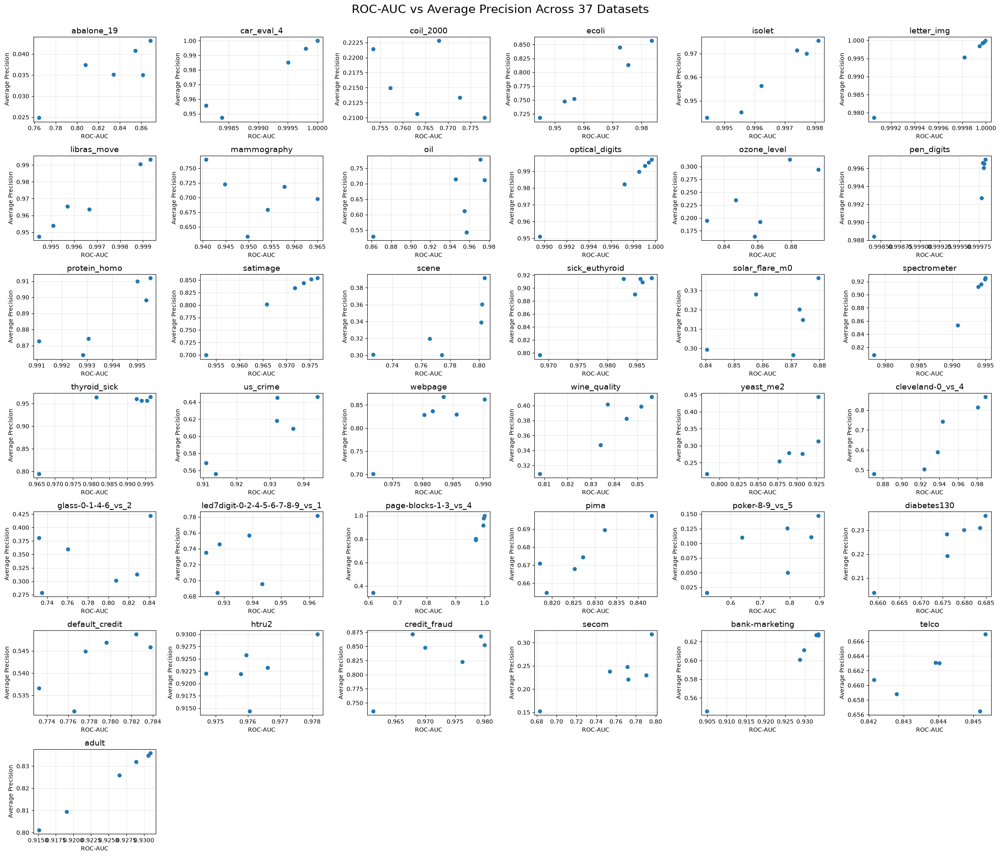

In [27]:
fig, axes = plt.subplots(nrows=7, ncols=6, figsize=(24, 20))
axes = axes.ravel()

for i, data in enumerate(datasets):
    df = create_df(scores_dict, data, models)
    ax = axes[i]

    roc_means = df.iloc[:, 0]
    ap_means = df.iloc[:, 2]

    ax.scatter(x=roc_means, y=ap_means)

    ax.set_title(data, fontsize=14)
    ax.set_xlabel('ROC-AUC', fontsize=10)
    ax.set_ylabel('Average Precision', fontsize=10)
    ax.grid(True, alpha=0.3)

for j in range(i+1, len(axes)):
    axes[j].axis('off')

plt.tight_layout()
plt.suptitle(f'ROC-AUC vs Average Precision Across {len(datasets)} Datasets', fontsize=20, y=1.02)
plt.savefig('../figures/ensembles_expanded_roc_vs_ap.png', dpi=300, bbox_inches='tight')
plt.show()

### ROC-AUC vs Average Precision

The scatter plots above show a clear positive relationship between ROC-AUC and Average Precision across all datasets: models that rank higher on ROC-AUC within a given dataset also tend to rank higher on Average Precision. This is consistent with theory — both metrics summarise the same underlying score ranking, but Average Precision weights high-precision operating points more heavily, making it more sensitive to how well the model separates the minority class at the top of its ranking.

## Recall Friedman test

In [28]:
friedman_rows = []
nemenyi_dict_recall = {}

for data in datasets:
    df = create_fold_df(folds_dict, data, "recall")
    statistic, pvalue = apply_friedman_test(df)
    friedman_rows.append({"dataset": data, "statistic": statistic, "pvalue": pvalue})

    # follow up with Nemenyi post-hoc test only when Friedman is significant
    if pvalue < 0.05:
        nemenyi_dict_recall[data] = apply_nemenyi_test(df)

friedman_df_recall = pd.DataFrame(friedman_rows).set_index("dataset")
friedman_df_recall

,statistic,pvalue
dataset,,
abalone_19,5.308219,0.379434
car_eval_4,5.000000,0.415880
coil_2000,2.041420,0.843385
ecoli,4.444444,0.487351
isolet,14.476744,0.012849
letter_img,20.838509,0.000869
libras_move,4.473684,0.483412
mammography,9.349112,0.095924
oil,7.916667,0.160888


## Plot Recall

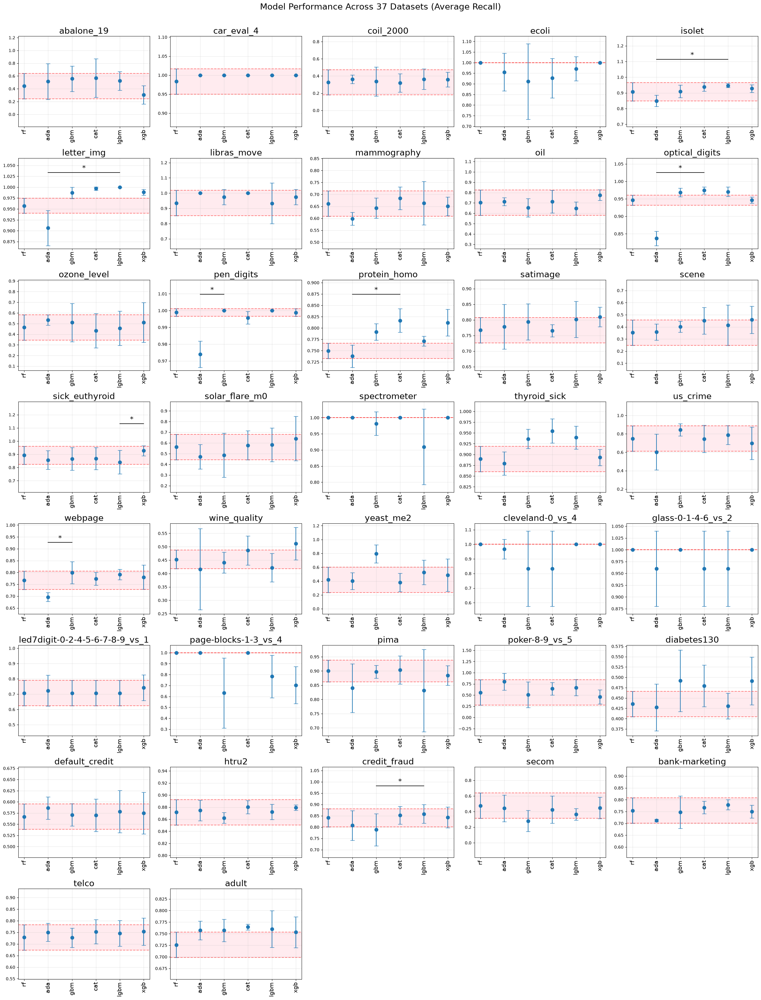

In [29]:
# Create figure with 37 subplots
fig, axes = plt.subplots(nrows=8, ncols=5, figsize=(25, 32))  # 8x5 grid for 37 plots (with 3 empty)
axes = axes.ravel()  # Flatten for easy iteration

# Loop through each DataFrame
for i, data in enumerate(datasets):
    df = create_df(scores_dict, data, models)
    
    ax = axes[i]
    
    # Extract data
    cls = df.index
    means = df.iloc[:, 6]
    stds = df.iloc[:, 7]

    upper = df.iloc[0, 6] + df.iloc[0, 7]
    lower = df.iloc[0, 6] - df.iloc[0, 7]

    # Determine significant comparisons (if any) up front, so we can
    # reserve extra headroom above the data for the significance bars
    best_model = None
    sig_models = []
    if data in nemenyi_dict_recall:
        best_model = means.idxmax()
        posthoc = nemenyi_dict_recall[data]
        sig_models = [
            m for m in models
            if m != best_model and posthoc.loc[best_model, m] < 0.05
        ]

    # Create errorbar plot
    ax.errorbar(x=cls, y=means, yerr=stds,
                fmt='o', capsize=5, markersize=8)

    # Customize subplot
    ax.set_title(data, fontsize=20)
    ylims = compute_ylim(means, stds, upper, lower)
    if sig_models:
        # reserve headroom above the data for the significance bars
        y0, y1 = ylims
        ylims = (y0, y1 + (y1 - y0) * 0.4)
    ax.set_ylim(ylims)
    ax.tick_params(axis='x', rotation=90, labelsize=14)
    ax.grid(True, alpha=0.3)

    # Add horizontal lines at RF error bars
    ax.axhline(y=upper, color='r', linestyle='--', alpha=0.5)
    ax.axhline(y=lower, color='r', linestyle='--', alpha=0.5)

    # Color area between RF error bars
    ax.axhspan(ymin=lower, ymax=upper, facecolor='pink', alpha=0.3)

    # If the Friedman test was significant, draw Nemenyi significance bars
    # from the best performing model to each model significantly worse than it
    if sig_models:
        data_max = (means + stds).max()
        add_significance_bars(ax, models, data_max, best_model, sig_models)

# Hide unused subplots
for j in range(i+1, len(axes)):
    axes[j].axis('off')

plt.tight_layout()
plt.suptitle(f'Model Performance Across {len(datasets)} Datasets (Average Recall)', fontsize=20, y=1.02)
plt.savefig('../figures/ensembles_expanded_recall.png', dpi=300, bbox_inches='tight')
plt.show()

### Recall conclusion

The Friedman test is significant for only 11 out of 37 datasets. Recall is measured at the threshold that maximises the F1-score, and on most datasets the models are statistically indistinguishable. `xgb` (2.8) and `cat` (3.0) have the best mean ranks.

## F1-score Friedman test

In [30]:
friedman_rows = []
nemenyi_dict_f1 = {}

for data in datasets:
    df = create_fold_df(folds_dict, data, "f1")
    statistic, pvalue = apply_friedman_test(df)
    friedman_rows.append({"dataset": data, "statistic": statistic, "pvalue": pvalue})

    # follow up with Nemenyi post-hoc test only when Friedman is significant
    if pvalue < 0.05:
        nemenyi_dict_f1[data] = apply_nemenyi_test(df)

friedman_df_f1 = pd.DataFrame(friedman_rows).set_index("dataset")
friedman_df_f1

,statistic,pvalue
dataset,,
abalone_19,4.885714,0.429987
car_eval_4,19.645669,0.001456
coil_2000,6.942857,0.224925
ecoli,8.987342,0.109570
isolet,13.620690,0.018207
letter_img,24.219653,0.000197
libras_move,6.525424,0.258393
mammography,14.080460,0.015106
oil,12.787879,0.025450


## Plot f1-score

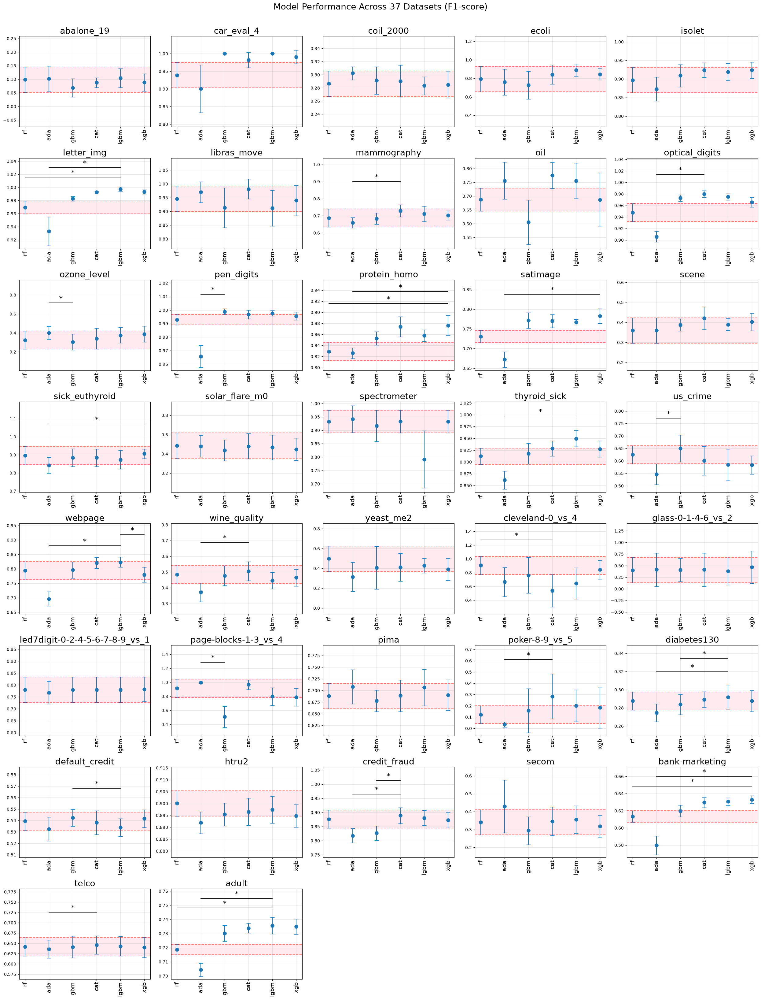

In [31]:
# Create figure with 37 subplots
fig, axes = plt.subplots(nrows=8, ncols=5, figsize=(25, 32))  # 8x5 grid for 37 plots (with 3 empty)
axes = axes.ravel()  # Flatten for easy iteration

# Loop through each DataFrame
for i, data in enumerate(datasets):
    df = create_df(scores_dict, data, models)
    
    ax = axes[i]
    
    # Extract data
    cls = df.index
    means = df.iloc[:, 8]
    stds = df.iloc[:, 9]

    upper = df.iloc[0, 8] + df.iloc[0, 9]
    lower = df.iloc[0, 8] - df.iloc[0, 9]

    # Determine significant comparisons (if any) up front, so we can
    # reserve extra headroom above the data for the significance bars
    best_model = None
    sig_models = []
    if data in nemenyi_dict_f1:
        best_model = means.idxmax()
        posthoc = nemenyi_dict_f1[data]
        sig_models = [
            m for m in models
            if m != best_model and posthoc.loc[best_model, m] < 0.05
        ]

    # Create errorbar plot
    ax.errorbar(x=cls, y=means, yerr=stds,
                fmt='o', capsize=5, markersize=8)

    # Customize subplot
    ax.set_title(data, fontsize=20)
    ylims = compute_ylim(means, stds, upper, lower)
    if sig_models:
        # reserve headroom above the data for the significance bars
        y0, y1 = ylims
        ylims = (y0, y1 + (y1 - y0) * 0.4)
    ax.set_ylim(ylims)
    ax.tick_params(axis='x', rotation=90, labelsize=14)
    ax.grid(True, alpha=0.3)

    # Add horizontal lines at RF error bars
    ax.axhline(y=upper, color='r', linestyle='--', alpha=0.5)
    ax.axhline(y=lower, color='r', linestyle='--', alpha=0.5)

    # Color area between RF error bars
    ax.axhspan(ymin=lower, ymax=upper, facecolor='pink', alpha=0.3)

    # If the Friedman test was significant, draw Nemenyi significance bars
    # from the best performing model to each model significantly worse than it
    if sig_models:
        data_max = (means + stds).max()
        add_significance_bars(ax, models, data_max, best_model, sig_models)

# Hide unused subplots
for j in range(i+1, len(axes)):
    axes[j].axis('off')

plt.tight_layout()
plt.suptitle(f'Model Performance Across {len(datasets)} Datasets (F1-score)', fontsize=20, y=1.02)
plt.savefig('../figures/ensembles_expanded_f1-score.png', dpi=300, bbox_inches='tight')
plt.show()

### F1-score conclusion

The Friedman test is significant for 26 out of 37 datasets. `cat` has the best mean rank (2.6) and is the best model on 10 datasets, followed by `lgbm` (3.0), `xgb` (3.2), `rf` (3.7), `gbm` (4.0) and `ada` (4.6). No model consistently tops the ranking across all problems.

## MCC Friedman test

In [32]:
friedman_rows = []
nemenyi_dict_mcc = {}

for data in datasets:
    df = create_fold_df(folds_dict, data, "mcc")
    statistic, pvalue = apply_friedman_test(df)
    friedman_rows.append({"dataset": data, "statistic": statistic, "pvalue": pvalue})

    # follow up with Nemenyi post-hoc test only when Friedman is significant
    if pvalue < 0.05:
        nemenyi_dict_mcc[data] = apply_nemenyi_test(df)

friedman_df_mcc = pd.DataFrame(friedman_rows).set_index("dataset")
friedman_df_mcc

,statistic,pvalue
dataset,,
abalone_19,7.857143,0.164286
car_eval_4,19.645669,0.001456
coil_2000,4.657143,0.459137
ecoli,8.694268,0.121898
isolet,14.252874,0.014080
letter_img,24.219653,0.000197
libras_move,6.525424,0.258393
mammography,15.924855,0.007062
oil,13.802395,0.016915


## Plot MCC

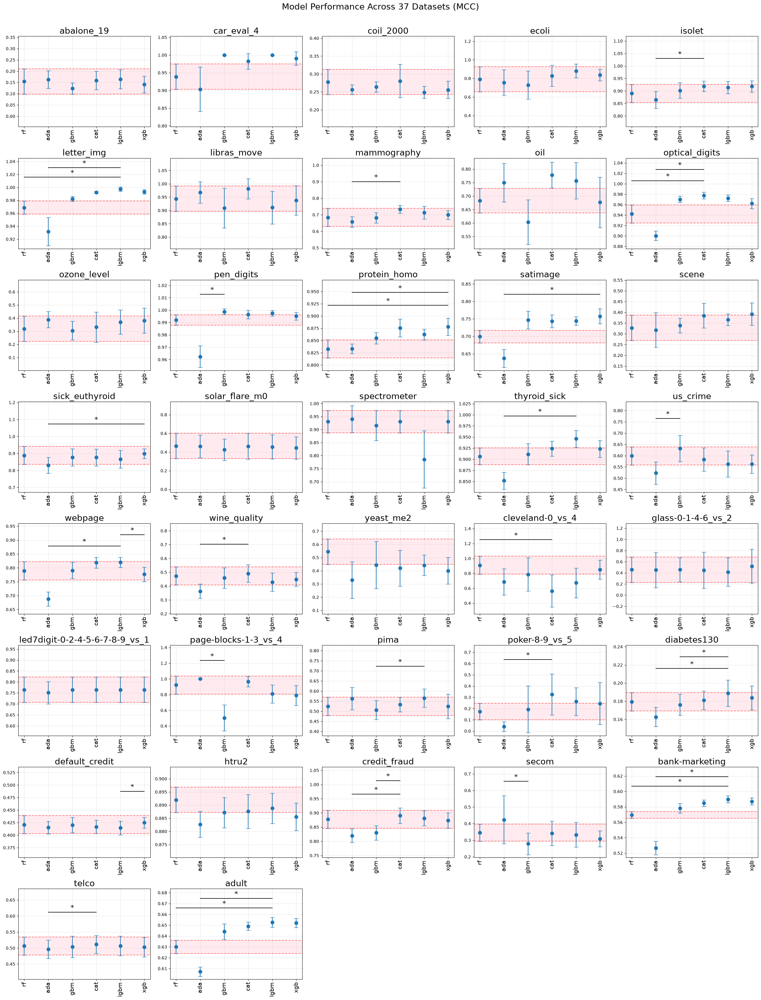

In [33]:
# Create figure with 37 subplots
fig, axes = plt.subplots(nrows=8, ncols=5, figsize=(25, 32))  # 8x5 grid for 37 plots (with 3 empty)
axes = axes.ravel()  # Flatten for easy iteration

# Loop through each DataFrame
for i, data in enumerate(datasets):
    df = create_df(scores_dict, data, models)
    
    ax = axes[i]
    
    # Extract data
    cls = df.index
    means = df.iloc[:, 10]
    stds = df.iloc[:, 11]

    upper = df.iloc[0, 10] + df.iloc[0, 11]
    lower = df.iloc[0, 10] - df.iloc[0, 11]

    # Determine significant comparisons (if any) up front, so we can
    # reserve extra headroom above the data for the significance bars
    best_model = None
    sig_models = []
    if data in nemenyi_dict_mcc:
        best_model = means.idxmax()
        posthoc = nemenyi_dict_mcc[data]
        sig_models = [
            m for m in models
            if m != best_model and posthoc.loc[best_model, m] < 0.05
        ]

    # Create errorbar plot
    ax.errorbar(x=cls, y=means, yerr=stds,
                fmt='o', capsize=5, markersize=8)

    # Customize subplot
    ax.set_title(data, fontsize=20)
    ylims = compute_ylim(means, stds, upper, lower)
    if sig_models:
        # reserve headroom above the data for the significance bars
        y0, y1 = ylims
        ylims = (y0, y1 + (y1 - y0) * 0.4)
    ax.set_ylim(ylims)
    ax.tick_params(axis='x', rotation=90, labelsize=14)
    ax.grid(True, alpha=0.3)

    # Add horizontal lines at RF error bars
    ax.axhline(y=upper, color='r', linestyle='--', alpha=0.5)
    ax.axhline(y=lower, color='r', linestyle='--', alpha=0.5)

    # Color area between RF error bars
    ax.axhspan(ymin=lower, ymax=upper, facecolor='pink', alpha=0.3)

    # If the Friedman test was significant, draw Nemenyi significance bars
    # from the best performing model to each model significantly worse than it
    if sig_models:
        data_max = (means + stds).max()
        add_significance_bars(ax, models, data_max, best_model, sig_models)

# Hide unused subplots
for j in range(i+1, len(axes)):
    axes[j].axis('off')

plt.tight_layout()
plt.suptitle(f'Model Performance Across {len(datasets)} Datasets (MCC)', fontsize=20, y=1.02)
plt.savefig('../figures/ensembles_expanded_mcc.png', dpi=300, bbox_inches='tight')
plt.show()

### MCC conclusion

Matthews Correlation Coefficient results are very similar to the F1-score, which is expected given that both aggregate TP, FP, TN and FN into a single number. The Friedman test is significant for 26 datasets. The test is not significant for `abalone_19`, `coil_2000`, `ecoli`, `libras_move`, `ozone_level`, `scene`, `solar_flare_m0`, `yeast_me2`, `glass-0-1-4-6_vs_2`, `led7digit-0-2-4-5-6-7-8-9_vs_1` and `htru2`, so on those datasets the models are interchangeable on MCC. Mean ranks: `cat` 2.6, `lgbm` 2.9, `xgb` 3.3, `rf` 3.5, `gbm` 4.1 and `ada` 4.7.

## Balanced Accuracy Friedman test

In [34]:
friedman_rows = []
nemenyi_dict_ba = {}

for data in datasets:
    df = create_fold_df(folds_dict, data, "ba")
    statistic, pvalue = apply_friedman_test(df)
    friedman_rows.append({"dataset": data, "statistic": statistic, "pvalue": pvalue})

    # follow up with Nemenyi post-hoc test only when Friedman is significant
    if pvalue < 0.05:
        nemenyi_dict_ba[data] = apply_nemenyi_test(df)

friedman_df_ba = pd.DataFrame(friedman_rows).set_index("dataset")
friedman_df_ba

,statistic,pvalue
dataset,,
abalone_19,10.257143,0.068269
car_eval_4,19.645669,0.001456
coil_2000,6.142857,0.292565
ecoli,7.088608,0.214133
isolet,16.666667,0.005177
letter_img,21.034483,0.000798
libras_move,6.525424,0.258393
mammography,20.771429,0.000895
oil,18.257143,0.002641


## Balanced accuracy

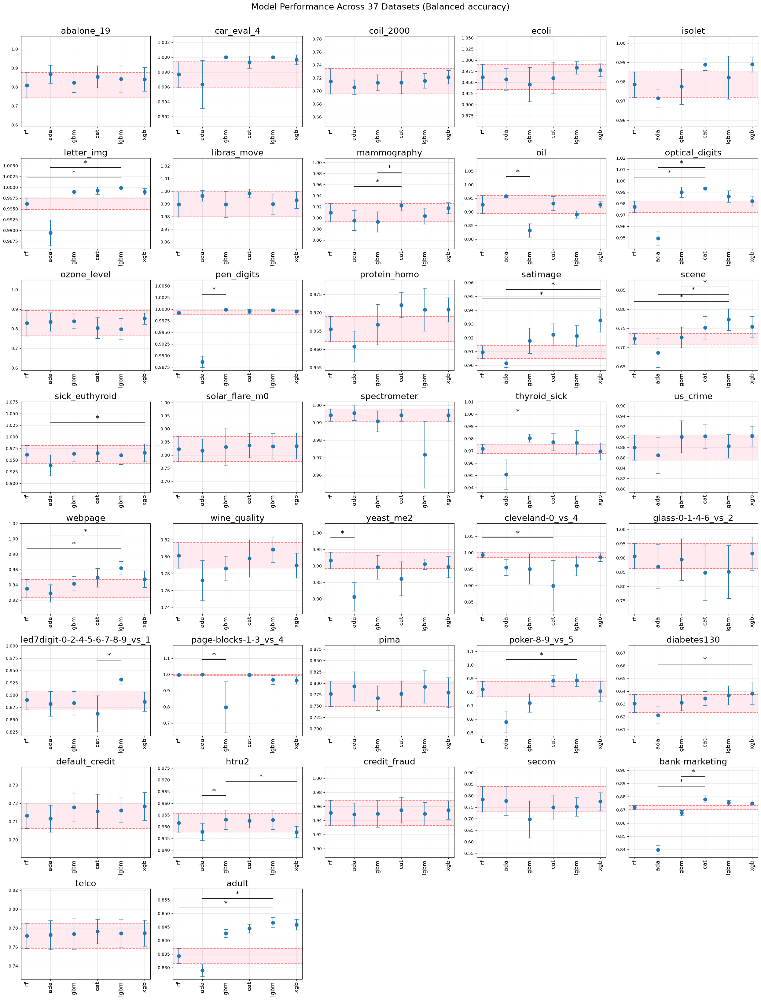

In [35]:
# Create figure with 37 subplots
fig, axes = plt.subplots(nrows=8, ncols=5, figsize=(25, 32))  # 8x5 grid for 37 plots (with 3 empty)
axes = axes.ravel()  # Flatten for easy iteration

# Loop through each DataFrame
for i, data in enumerate(datasets):
    df = create_df(scores_dict, data, models)
    
    ax = axes[i]
    
    # Extract data
    cls = df.index
    means = df.iloc[:, 12]
    stds = df.iloc[:, 13]

    upper = df.iloc[0, 12] + df.iloc[0, 13]
    lower = df.iloc[0, 12] - df.iloc[0, 13]

    # Determine significant comparisons (if any) up front, so we can
    # reserve extra headroom above the data for the significance bars
    best_model = None
    sig_models = []
    if data in nemenyi_dict_ba:
        best_model = means.idxmax()
        posthoc = nemenyi_dict_ba[data]
        sig_models = [
            m for m in models
            if m != best_model and posthoc.loc[best_model, m] < 0.05
        ]

    # Create errorbar plot
    ax.errorbar(x=cls, y=means, yerr=stds,
                fmt='o', capsize=5, markersize=8)

    # Customize subplot
    ax.set_title(data, fontsize=20)
    ylims = compute_ylim(means, stds, upper, lower)
    if sig_models:
        # reserve headroom above the data for the significance bars
        y0, y1 = ylims
        ylims = (y0, y1 + (y1 - y0) * 0.4)
    ax.set_ylim(ylims)
    ax.tick_params(axis='x', rotation=90, labelsize=14)
    ax.grid(True, alpha=0.3)

    # Add horizontal lines at RF error bars
    ax.axhline(y=upper, color='r', linestyle='--', alpha=0.5)
    ax.axhline(y=lower, color='r', linestyle='--', alpha=0.5)

    # Color area between RF error bars
    ax.axhspan(ymin=lower, ymax=upper, facecolor='pink', alpha=0.3)

    # If the Friedman test was significant, draw Nemenyi significance bars
    # from the best performing model to each model significantly worse than it
    if sig_models:
        data_max = (means + stds).max()
        add_significance_bars(ax, models, data_max, best_model, sig_models)

# Hide unused subplots
for j in range(i+1, len(axes)):
    axes[j].axis('off')

plt.tight_layout()
plt.suptitle(f'Model Performance Across {len(datasets)} Datasets (Balanced accuracy)', fontsize=20, y=1.02)
plt.savefig('../figures/ensembles_expanded_balanced_acc.png', dpi=300, bbox_inches='tight')
plt.show()

### Balanced Accuracy conclusion

The Friedman test is significant for 25 out of 37 datasets. It is not significant for `abalone_19`, `coil_2000`, `ecoli`, `libras_move`, `solar_flare_m0`, `us_crime`, `wine_quality`, `glass-0-1-4-6_vs_2`, `pima`, `default_credit`, `credit_fraud` and `telco`, where all models achieve similar per-class recall. `xgb` has the best mean rank (2.6) and is the best model on 10 datasets, followed by `lgbm` (2.8), `cat` (2.9), `rf` (3.9) and `gbm` (4.0). `ada` is last (4.8).

## Brier Score Friedman test

In [36]:
friedman_rows = []
nemenyi_dict_brier = {}

for data in datasets:
    df = create_fold_df(folds_dict, data, "brier")
    statistic, pvalue = apply_friedman_test(df)
    friedman_rows.append({"dataset": data, "statistic": statistic, "pvalue": pvalue})

    # follow up with Nemenyi post-hoc test only when Friedman is significant
    if pvalue < 0.05:
        nemenyi_dict_brier[data] = apply_nemenyi_test(df)

friedman_df_brier = pd.DataFrame(friedman_rows).set_index("dataset")
friedman_df_brier

,statistic,pvalue
dataset,,
abalone_19,22.371429,0.000445
car_eval_4,24.085714,0.000209
coil_2000,17.800000,0.003208
ecoli,19.057143,0.001876
isolet,23.628571,0.000256
letter_img,24.314286,0.000189
libras_move,20.200000,0.001146
mammography,23.171429,0.000313
oil,21.571429,0.000631


## Brier score

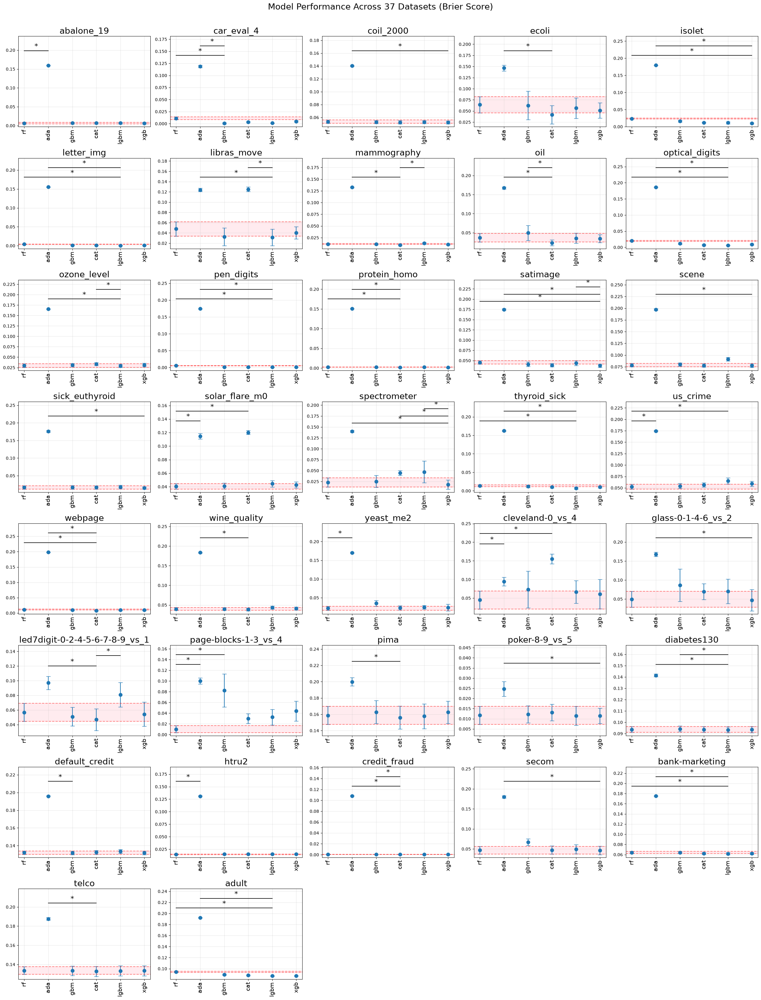

In [37]:
# Create figure with 37 subplots
fig, axes = plt.subplots(nrows=8, ncols=5, figsize=(25, 32))  # 8x5 grid for 37 plots (with 3 empty)
axes = axes.ravel()  # Flatten for easy iteration

# Loop through each DataFrame
for i, data in enumerate(datasets):
    df = create_df(scores_dict, data, models)
    
    ax = axes[i]
    
    # Extract data
    cls = df.index
    means = df.iloc[:, 14]
    stds = df.iloc[:, 15]

    upper = df.iloc[0, 14] + df.iloc[0, 15]
    lower = df.iloc[0, 14] - df.iloc[0, 15]

    # Determine significant comparisons (if any) up front, so we can
    # reserve extra headroom above the data for the significance bars
    best_model = None
    sig_models = []
    if data in nemenyi_dict_brier:
        best_model = means.idxmin()
        posthoc = nemenyi_dict_brier[data]
        sig_models = [
            m for m in models
            if m != best_model and posthoc.loc[best_model, m] < 0.05
        ]

    # Create errorbar plot
    ax.errorbar(x=cls, y=means, yerr=stds,
                fmt='o', capsize=5, markersize=8)

    # Customize subplot
    ax.set_title(data, fontsize=20)
    ylims = compute_ylim(means, stds, upper, lower)
    if sig_models:
        # reserve headroom above the data for the significance bars
        y0, y1 = ylims
        ylims = (y0, y1 + (y1 - y0) * 0.4)
    ax.set_ylim(ylims)
    ax.tick_params(axis='x', rotation=90, labelsize=14)
    ax.grid(True, alpha=0.3)

    # Add horizontal lines at RF error bars
    ax.axhline(y=upper, color='r', linestyle='--', alpha=0.5)
    ax.axhline(y=lower, color='r', linestyle='--', alpha=0.5)

    # Color area between RF error bars
    ax.axhspan(ymin=lower, ymax=upper, facecolor='pink', alpha=0.3)

    # If the Friedman test was significant, draw Nemenyi significance bars
    # from the best performing model to each model significantly worse than it
    if sig_models:
        data_max = (means + stds).max()
        add_significance_bars(ax, models, data_max, best_model, sig_models)

# Hide unused subplots
for j in range(i+1, len(axes)):
    axes[j].axis('off')

plt.tight_layout()
plt.suptitle(f'Model Performance Across {len(datasets)} Datasets (Brier Score)', fontsize=20, y=1.02)
plt.savefig('../figures/ensembles_expanded_brier.png', dpi=300, bbox_inches='tight')
plt.show()

### Brier Score conclusion

The Brier score produces the strongest statistical signal of all metrics: the Friedman test is significant on all 37 datasets. The Brier score depends on the calibration of the predicted probabilities, and the models differ most in how they output probabilities. `xgb` (mean rank 2.5) and `cat` (2.7) have the lowest Brier scores, followed by `lgbm` (3.1), `rf` (3.4) and `gbm` (3.5). AdaBoost is clearly last (5.9) and is never the best model, because its probabilities are squeezed towards the centre. Probability calibration is where model choice matters most, even when ranking metrics show only modest differences.

## Join datasets and create table

In [38]:
dfs = [create_df(scores_dict, data, models) for data in datasets]
names = datasets
result = pd.concat(dfs, keys=names, names=['dataset', 'model'])
result

roc   roc_std        ap    ap_std  precision  \
dataset    model                                                      
abalone_19 rf     0.807908  0.092538  0.037444  0.018438   0.056745   
           ada    0.868558  0.044778  0.043142  0.017950   0.067248   
           gbm    0.764283  0.098548  0.024849  0.012160   0.039047   
           cat    0.861609  0.045691  0.035047  0.007211   0.048529   
           lgbm   0.854428  0.061518  0.040814  0.015890   0.060209   
...                    ...       ...       ...       ...        ...   
adult      ada    0.915118  0.001951  0.801170  0.005085   0.659116   
           gbm    0.926524  0.001574  0.825900  0.005309   0.706611   
           cat    0.928917  0.001298  0.831923  0.003670   0.705500   
           lgbm   0.930914  0.001059  0.835919  0.003067   0.715567   
           xgb    0.930616  0.001275  0.834826  0.003453   0.719145   

                  precision_std    recall  recall_std  f1_score    f1_std  \
dataset    model                                                            
abalone_19 rf          0.028469  0.442381    0.198271  0.098943  0.046668   
           ada         0.038081  0.514286    0.280346  0.102454  0.045972   
           gbm         0.022351  0.557619    0.198271  0.068805  0.033539   
           cat         0.008566  0.566190    0.301427  0.087842  0.018152   
           lgbm        0.024313  0.522857    0.147555  0.104623  0.035150   
...                         ...       ...         ...       ...       ...   
adult      ada         0.011499  0.757068    0.020423  0.704381  0.004653   
           gbm         0.028949  0.757227    0.024048  0.730107  0.005560   
           cat         0.006024  0.764458    0.006213  0.733762  0.003493   
           lgbm        0.031710  0.760265    0.039668  0.735543  0.005739   
           xgb         0.020526  0.753200    0.033153  0.734821  0.005404   

                       mcc   mcc_std        ba    ba_std     brier  brier_std  \
dataset    model                                                                
abalone_19 rf     0.154355  0.056203  0.808797  0.066870  0.006558   0.001798   
           ada    0.162647  0.039149  0.867453  0.048209  0.159425   0.001084   
           gbm    0.122859  0.025285  0.823302  0.051489  0.006648   0.001844   
           cat    0.158317  0.040425  0.853151  0.057914  0.006746   0.001893   
           lgbm   0.164191  0.042038  0.842408  0.068918  0.006789   0.001866   
...                    ...       ...       ...       ...       ...        ...   
adult      ada    0.607099  0.004295  0.829043  0.002271  0.192003   0.000520   
           gbm    0.644071  0.007101  0.842622  0.001451  0.089223   0.001207   
           cat    0.649061  0.003806  0.844427  0.001616  0.087903   0.000797   
           lgbm   0.652536  0.004491  0.846614  0.001856  0.086895   0.000799   
           xgb    0.652132  0.004297  0.845865  0.001976  0.087129   0.000692   

                     gmean  gmean_std    thresh  tresh_std  
dataset    model                                            
abalone_19 rf     0.796202   0.069239  0.022879   0.001893  
           ada    0.855384   0.056777  0.451197   0.018711  
           gbm    0.819805   0.048136  0.022970   0.017382  
           cat    0.844974   0.060935  0.023478   0.010718  
           lgbm   0.834627   0.071210  0.024622   0.019588  
...                    ...        ...       ...        ...  
adult      ada    0.827622   0.002442  0.483614   0.002586  
           gbm    0.841999   0.001464  0.372639   0.032573  
           cat    0.842905   0.002129  0.367041   0.005756  
           lgbm   0.845774   0.002032  0.383238   0.052005  
           xgb    0.845212   0.002268  0.386767   0.039661  

[222 rows x 20 columns]

In [39]:
result['roc_±_std'] = result['roc'].round(3).astype(str) + '_±_' + result['roc_std'].round(3).astype(str)
result['ap_±_td'] = result['ap'].round(3).astype(str) + '_±_' + result['ap_std'].round(3).astype(str)
result['f1_±_std'] = result['f1_score'].round(3).astype(str) + '_±_' + result['f1_std'].round(3).astype(str)
result['mcc_±_td'] = result['mcc'].round(3).astype(str) + '_±_' + result['mcc_std'].round(3).astype(str)
result['ba_±_std'] = result['ba'].round(3).astype(str) + '_±_' + result['ba_std'].round(3).astype(str)
result['brier_±_td'] = result['brier'].round(3).astype(str) + '_±_' + result['brier_std'].round(3).astype(str)
result['gmean_±_std'] = result['gmean'].round(3).astype(str) + '_±_' + result['gmean_std'].round(3).astype(str)
result['thresh_±_std'] = result['thresh'].round(3).astype(str) + '_±_' + result['tresh_std'].round(3).astype(str)

result.to_csv('../results/ensembles_expanded_models_performance.csv', index=True)

result[['roc_±_std', 'ap_±_td', 'f1_±_std', 'mcc_±_td']]

roc_±_std        ap_±_td       f1_±_std       mcc_±_td
dataset    model                                                            
abalone_19 rf     0.808_±_0.093  0.037_±_0.018  0.099_±_0.047  0.154_±_0.056
           ada    0.869_±_0.045  0.043_±_0.018  0.102_±_0.046  0.163_±_0.039
           gbm    0.764_±_0.099  0.025_±_0.012  0.069_±_0.034  0.123_±_0.025
           cat    0.862_±_0.046  0.035_±_0.007  0.088_±_0.018   0.158_±_0.04
           lgbm   0.854_±_0.062  0.041_±_0.016  0.105_±_0.035  0.164_±_0.042
...                         ...            ...            ...            ...
adult      ada    0.915_±_0.002  0.801_±_0.005  0.704_±_0.005  0.607_±_0.004
           gbm    0.927_±_0.002  0.826_±_0.005   0.73_±_0.006  0.644_±_0.007
           cat    0.929_±_0.001  0.832_±_0.004  0.734_±_0.003  0.649_±_0.004
           lgbm   0.931_±_0.001  0.836_±_0.003  0.736_±_0.006  0.653_±_0.004
           xgb    0.931_±_0.001  0.835_±_0.003  0.735_±_0.005  0.652_±_0.004

[222 rows x 4 columns]

## Comparison with the models trained with successive halving (SH)

`results_previous_tuning` holds the test-set results of the models trained before this
change, when all six models were tuned with successive halving over the number of trees
and `gbm` had no early stopping. `rf` and `ada` are tuned the same way in both runs, so
they should not change.

For each model and metric, the table shows the median difference (new - SH) across
datasets, the number of datasets where the new model is better (higher ROC-AUC and AP,
lower Brier score), and the p-value of a paired Wilcoxon signed-rank test across
datasets.

In [40]:
from scipy.stats import wilcoxon

with open('../models/ensembles/results_previous_tuning', 'rb') as f:
    scores_prev = pickle.load(f)

new = pd.concat([create_df(scores_dict, d, models) for d in datasets], keys=datasets, names=["dataset", "model"])
prev = pd.concat([create_df(scores_prev, d, models) for d in datasets], keys=datasets, names=["dataset", "model"])

rows = []
for m in models:
    for metric, sign in [("roc", 1), ("ap", 1), ("brier", -1)]:
        n = new.xs(m, level="model")[metric]
        p = prev.xs(m, level="model")[metric]
        diff = n - p
        rows.append({
            "model": m, "metric": metric,
            "median_diff": diff.median(),
            "n_better": int((sign * diff > 0).sum()),
            "n_worse": int((sign * diff < 0).sum()),
            "wilcoxon_p": wilcoxon(n, p).pvalue if (diff != 0).any() else np.nan,
        })

comparison_df = pd.DataFrame(rows).set_index(["metric", "model"]).sort_index(level=0, sort_remaining=False)
comparison_df.round(4)

median_diff  n_better  n_worse  wilcoxon_p
metric model                                            
ap     rf          0.0000         0        0         NaN
       ada         0.0000         0        0         NaN
       gbm        -0.0082         8       28      0.0026
       cat         0.0045        24       13      0.2304
       lgbm       -0.0009        16       20      0.2204
       xgb         0.0009        19       18      0.8580
brier  rf          0.0000         7        6      0.8604
       ada         0.0000         2        1      0.5930
       gbm         0.0002        17       20      0.7770
       cat        -0.0012        26       11      0.0827
       lgbm        0.0002        17       20      0.7884
       xgb         0.0000        18       19      0.3460
roc    rf          0.0000         0        0         NaN
       ada         0.0000         0        0         NaN
       gbm        -0.0002        14       22      0.2998
       cat         0.0003        24       13      0.2246
       lgbm        0.0002        20       16      0.2647
       xgb         0.0004        21       16      0.5405

### ROC-AUC per dataset: SH vs new

ROC-AUC on the test set (mean ± std across the bootstrap samples) of the models trained
with successive halving (SH) and of the current models (new).

In [41]:
def mean_std(df):
    return df["roc"].map("{:.3f}".format) + " ± " + df["roc_std"].map("{:.3f}".format)


roc_table = pd.concat(
    {
        m: pd.DataFrame({
            "SH": mean_std(prev.xs(m, level="model")),
            "new": mean_std(new.xs(m, level="model")),
        })
        for m in models
    },
    axis=1,
)
roc_table

rf                           ada  \
                                           SH            new             SH   
dataset                                                                       
abalone_19                      0.808 ± 0.093  0.808 ± 0.093  0.869 ± 0.045   
car_eval_4                      0.998 ± 0.001  0.998 ± 0.001  0.998 ± 0.003   
coil_2000                       0.757 ± 0.018  0.757 ± 0.018  0.753 ± 0.021   
ecoli                           0.957 ± 0.033  0.957 ± 0.033  0.953 ± 0.035   
isolet                          0.996 ± 0.002  0.996 ± 0.002  0.994 ± 0.001   
letter_img                      1.000 ± 0.000  1.000 ± 0.000  0.999 ± 0.000   
libras_move                     0.996 ± 0.004  0.996 ± 0.004  0.999 ± 0.001   
mammography                     0.965 ± 0.012  0.965 ± 0.012  0.950 ± 0.012   
oil                             0.955 ± 0.022  0.955 ± 0.022  0.975 ± 0.007   
optical_digits                  0.997 ± 0.001  0.997 ± 0.001  0.990 ± 0.002   
ozone_level                     0.862 ± 0.057  0.862 ± 0.057  0.879 ± 0.038   
pen_digits                      1.000 ± 0.000  1.000 ± 0.000  0.998 ± 0.001   
protein_homo                    0.991 ± 0.002  0.991 ± 0.002  0.993 ± 0.002   
satimage                        0.966 ± 0.002  0.966 ± 0.002  0.953 ± 0.005   
scene                           0.766 ± 0.031  0.766 ± 0.031  0.727 ± 0.048   
sick_euthyroid                  0.983 ± 0.012  0.983 ± 0.012  0.969 ± 0.015   
solar_flare_m0                  0.873 ± 0.058  0.873 ± 0.058  0.858 ± 0.042   
spectrometer                    0.994 ± 0.004  0.994 ± 0.004  0.995 ± 0.005   
thyroid_sick                    0.995 ± 0.001  0.995 ± 0.001  0.966 ± 0.013   
us_crime                        0.932 ± 0.019  0.932 ± 0.019  0.914 ± 0.016   
webpage                         0.986 ± 0.003  0.986 ± 0.003  0.972 ± 0.008   
wine_quality                    0.856 ± 0.011  0.856 ± 0.011  0.808 ± 0.026   
yeast_me2                       0.927 ± 0.035  0.927 ± 0.035  0.784 ± 0.096   
cleveland-0_vs_4                0.989 ± 0.014  0.989 ± 0.014  0.938 ± 0.055   
glass-0-1-4-6_vs_2              0.828 ± 0.099  0.828 ± 0.099  0.760 ± 0.168   
led7digit-0-2-4-5-6-7-8-9_vs_1  0.943 ± 0.018  0.943 ± 0.018  0.928 ± 0.021   
page-blocks-1-3_vs_4            0.996 ± 0.005  0.996 ± 0.005  1.000 ± 0.000   
pima                            0.825 ± 0.028  0.825 ± 0.028  0.843 ± 0.032   
poker-8-9_vs_5                  0.793 ± 0.069  0.793 ± 0.069  0.520 ± 0.085   
diabetes130                     0.676 ± 0.007  0.676 ± 0.007  0.659 ± 0.007   
default_credit                  0.784 ± 0.007  0.784 ± 0.007  0.773 ± 0.006   
htru2                           0.976 ± 0.006  0.976 ± 0.006  0.976 ± 0.004   
credit_fraud                    0.970 ± 0.010  0.970 ± 0.010  0.976 ± 0.006   
secom                           0.790 ± 0.060  0.790 ± 0.060  0.796 ± 0.076   
bank-marketing                  0.929 ± 0.003  0.929 ± 0.003  0.905 ± 0.004   
telco                           0.845 ± 0.013  0.845 ± 0.013  0.843 ± 0.013   
adult                           0.919 ± 0.002  0.919 ± 0.002  0.915 ± 0.002   

                                                         gbm                 \
                                          new             SH            new   
dataset                                                                       
abalone_19                      0.869 ± 0.045  0.808 ± 0.060  0.764 ± 0.099   
car_eval_4                      0.998 ± 0.003  1.000 ± 0.000  1.000 ± 0.000   
coil_2000                       0.753 ± 0.021  0.757 ± 0.017  0.763 ± 0.009   
ecoli                           0.953 ± 0.035  0.960 ± 0.030  0.945 ± 0.044   
isolet                          0.994 ± 0.001  0.998 ± 0.001  0.996 ± 0.002   
letter_img                      0.999 ± 0.000  1.000 ± 0.000  1.000 ± 0.000   
libras_move                     0.999 ± 0.001  0.994 ± 0.005  0.995 ± 0.004   
mammography                     0.950 ± 0.012  0.952 ± 0.010  0.954 ± 0.014   
oil          

In [42]:
# datasets where cat, lgbm and xgb all have ROC-AUC < 0.95, with both SH and new tuning
boosters = ["cat", "lgbm", "xgb"]
low_roc = [
    d for d in datasets
    if (prev.loc[d].loc[boosters, "roc"] < 0.95).all()
    and (new.loc[d].loc[boosters, "roc"] < 0.95).all()
]
roc_table.loc[low_roc]

rf                           ada  \
                               SH            new             SH   
dataset                                                           
abalone_19          0.808 ± 0.093  0.808 ± 0.093  0.869 ± 0.045   
coil_2000           0.757 ± 0.018  0.757 ± 0.018  0.753 ± 0.021   
ozone_level         0.862 ± 0.057  0.862 ± 0.057  0.879 ± 0.038   
scene               0.766 ± 0.031  0.766 ± 0.031  0.727 ± 0.048   
solar_flare_m0      0.873 ± 0.058  0.873 ± 0.058  0.858 ± 0.042   
us_crime            0.932 ± 0.019  0.932 ± 0.019  0.914 ± 0.016   
wine_quality        0.856 ± 0.011  0.856 ± 0.011  0.808 ± 0.026   
yeast_me2           0.927 ± 0.035  0.927 ± 0.035  0.784 ± 0.096   
glass-0-1-4-6_vs_2  0.828 ± 0.099  0.828 ± 0.099  0.760 ± 0.168   
pima                0.825 ± 0.028  0.825 ± 0.028  0.843 ± 0.032   
poker-8-9_vs_5      0.793 ± 0.069  0.793 ± 0.069  0.520 ± 0.085   
diabetes130         0.676 ± 0.007  0.676 ± 0.007  0.659 ± 0.007   
default_credit      0.784 ± 0.007  0.784 ± 0.007  0.773 ± 0.006   
secom               0.790 ± 0.060  0.790 ± 0.060  0.796 ± 0.076   
bank-marketing      0.929 ± 0.003  0.929 ± 0.003  0.905 ± 0.004   
telco               0.845 ± 0.013  0.845 ± 0.013  0.843 ± 0.013   
adult               0.919 ± 0.002  0.919 ± 0.002  0.915 ± 0.002   

                                             gbm                 \
                              new             SH            new   
dataset                                                           
abalone_19          0.869 ± 0.045  0.808 ± 0.060  0.764 ± 0.099   
coil_2000           0.753 ± 0.021  0.757 ± 0.017  0.763 ± 0.009   
ozone_level         0.879 ± 0.038  0.863 ± 0.058  0.858 ± 0.045   
scene               0.727 ± 0.048  0.783 ± 0.029  0.774 ± 0.023   
solar_flare_m0      0.858 ± 0.042  0.872 ± 0.051  0.840 ± 0.071   
us_crime            0.914 ± 0.016  0.912 ± 0.027  0.944 ± 0.017   
wine_quality        0.808 ± 0.026  0.837 ± 0.015  0.834 ± 0.017   
yeast_me2           0.784 ± 0.096  0.793 ± 0.111  0.877 ± 0.059   
glass-0-1-4-6_vs_2  0.760 ± 0.168  0.787 ± 0.126  0.807 ± 0.146   
pima                0.843 ± 0.032  0.831 ± 0.024  0.817 ± 0.036   
poker-8-9_vs_5      0.520 ± 0.085  0.895 ± 0.049  0.638 ± 0.140   
diabetes130         0.659 ± 0.007  0.673 ± 0.007  0.676 ± 0.006   
default_credit      0.773 ± 0.006  0.769 ± 0.007  0.782 ± 0.005   
secom               0.796 ± 0.076  0.796 ± 0.062  0.683 ± 0.088   
bank-marketing      0.905 ± 0.004  0.931 ± 0.002  0.930 ± 0.003   
telco               0.843 ± 0.013  0.841 ± 0.012  0.842 ± 0.015   
adult               0.915 ± 0.002  0.921 ± 0.002  0.927 ± 0.002   

                              cat                          lgbm  \
                               SH            new             SH   
dataset                                                           
abalone_19          0.852 ± 0.043  0.862 ± 0.046  0.808 ± 0.070   
coil_2000           0.747 ± 0.018  0.768 ± 0.017  0.750 ± 0.020   
ozone_level         0.866 ± 0.051  0.830 ± 0.069  0.867 ± 0.038   
scene               0.730 ± 0.051  0.802 ± 0.034  0.803 ± 0.027   
solar_flare_m0      0.868 ± 0.056  0.874 ± 0.059  0.868 ± 0.054   
us_crime            0.930 ± 0.014  0.932 ± 0.023  0.931 ± 0.011   
wine_quality        0.838 ± 0.007  0.852 ± 0.017  0.854 ± 0.014   
yeast_me2           0.895 ± 0.040  0.889 ± 0.053  0.794 ± 0.093   
glass-0-1-4-6_vs_2  0.799 ± 0.146  0.732 ± 0.209  0.613 ± 0.295   
pima                0.822 ± 0.031  0.832 ± 0.029  0.797 ± 0.033   
poker-8-9_vs_5      0.936 ± 0.030  0.897 ± 0.048  0.933 ± 0.040   
diabetes130         0.666 ± 0.006  0.680 ± 0.006  0.673 ± 0.007   
default_credit      0.763 ± 0.008  0.778 ± 0.007  0.755 ± 0.005   
secom               0.747 ± 0.052  0.754 ± 0.042  0.792 ± 0.069   
bank-marketing      0.924 ± 0.002  0.934 ± 0.003  0.925 ± 0.001   
telco               0.832 ± 0.013  0.845 ± 0.014  0.841 ± 0.013   
adult               0.922 ± 0.002  0.929 ± 0.001  0.922 ± 0.002   

        

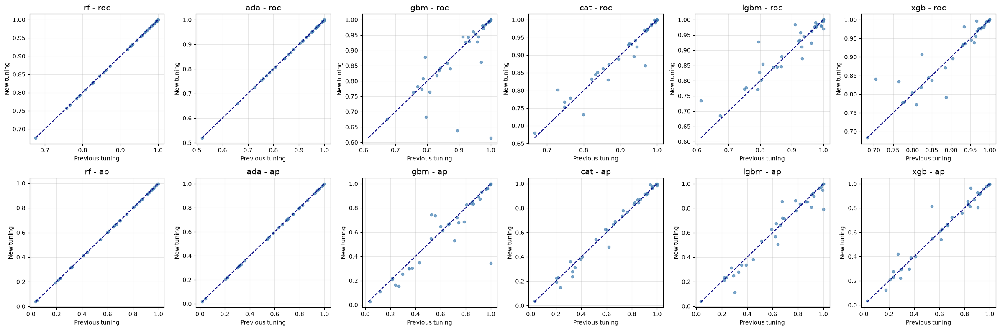

In [43]:
fig, axes = plt.subplots(2, len(models), figsize=(4 * len(models), 8))

for row, metric in enumerate(["roc", "ap"]):
    for ax, m in zip(axes[row], models):
        x = prev.xs(m, level="model")[metric]
        y = new.xs(m, level="model")[metric]
        ax.scatter(x, y, s=20, color="steelblue", alpha=0.7)
        lims = [min(x.min(), y.min()), max(x.max(), y.max())]
        ax.plot(lims, lims, color="navy", linestyle="--")
        ax.set_title(f"{m} - {metric}", fontsize=14)
        ax.set_xlabel("Previous tuning")
        ax.set_ylabel("New tuning")
        ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('../figures/ensembles_expanded_new_vs_previous_tuning.png', dpi=300, bbox_inches='tight')
plt.show()

In [44]:
# datasets where ROC-AUC changed the most (new - previous)
roc_diff = (new["roc"] - prev["roc"]).unstack("model")[models]
roc_diff.loc[roc_diff.abs().max(axis=1).sort_values(ascending=False).index].head(10).round(3)

model,rf,ada,gbm,cat,lgbm,xgb
dataset,,,,,,
page-blocks-1-3_vs_4,0.0,0.0,-0.385,-0.001,-0.030,0.003
poker-8-9_vs_5,0.0,0.0,-0.257,-0.040,-0.060,-0.095
glass-0-1-4-6_vs_2,0.0,0.0,0.021,-0.067,0.122,0.137
yeast_me2,0.0,0.0,0.084,-0.006,0.133,0.083
secom,0.0,0.0,-0.112,0.007,-0.020,-0.037
oil,0.0,0.0,-0.108,0.006,0.007,-0.007
cleveland-0_vs_4,0.0,0.0,0.015,-0.097,-0.038,0.047
ecoli,0.0,0.0,-0.016,-0.001,0.073,0.005
scene,0.0,0.0,-0.009,0.072,-0.001,0.004


### Comparison conclusion

- **`rf`** and **`ada`** give identical ROC-AUC and AP in both runs. This confirms that the comparison is like for like.
- **`cat`**, **`lgbm`** and **`xgb`** show no significant change on any metric. The median change in ROC-AUC is below 0.001, and the new models are better on slightly more datasets than they are worse (ROC-AUC: `cat` 24 vs 13, `lgbm` 20 vs 16, `xgb` 21 vs 16). The larger changes, in both directions, are on small datasets with large standard deviations (`glass-0-1-4-6_vs_2`, `yeast_me2`, `cleveland-0_vs_4`, `poker-8-9_vs_5`).
- **`gbm`** has the same ROC-AUC on most datasets (p = 0.30), but it is worse on AP (28 datasets, median -0.008, p = 0.003). It drops sharply on a few small datasets: `page-blocks-1-3_vs_4` (-0.39), `poker-8-9_vs_5` (-0.26), `secom` (-0.11) and `oil` (-0.11). The scikit-learn GBM stops on an internal validation split of 10% of the training data, which on these datasets holds only a handful of minority samples, so the stopping point is noisy.

The new procedure performs as well as successive halving for CatBoost, LightGBM and XGBoost. Early stopping in the scikit-learn GBM saves time, but costs performance on small datasets.